# Routing points from Census housing units and LODES jobs: New York and Houston

05.3 and 05.3.1 gave every tract one routing point, placed at the mean of its blocks' internal
points weighted by the resident workers of the LODES flows, and used it at both ends of every
commute. That has two weaknesses. The residence side of LODES is modelled by the Census for
confidentiality, so the weights are a synthetic allocation of workers to blocks. And the point
follows residents, so at the work end it can sit in the housing of a tract whose jobs are an
office park on the other side.

This notebook builds two points per tract instead. The home point weights the blocks by their
2020 Census housing units, a count the Census kept exact at block level when it protected the
2020 tables. The work point weights the blocks by the jobs located in them, summed over the
workplace side of the LODES file, which is the employer address with mild noise rather than a
model. Both use the block internal points already in the LODES crosswalk. Each step compares
the new points with the old one, and checks the tracts whose residents transit does not reach.

| Step | What we do |
|---|---|
| 1. Census block counts | Housing units and population of every block in the kept counties, from the 2020 TIGER/Line block files, saved beside the other inputs |
| 2. Two points per tract | The housing-weighted home point and the jobs-weighted work point, replaced by the tract's medoid when the mean lands on a block with no housing or no jobs; how far each moved from the old point |
| 2b. The switched tracts | How many means fell on an empty block and were replaced by the medoid, per area and per point, and where they are |
| 3. Snapping | Both points moved onto a street inside their tract, with the rule of 05.3, and saved for the routing |
| 4. Transit routing | The transit matrix rerun from home points to work points, into a separate folder, and the unreached commutes compared with 05.3, which routed one resident-weighted point at both ends |


In [1]:
import time
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from matplotlib.patches import Patch


## 1. Census block counts

The 2020 Census counted, per block, the total population and the total housing units. The
Census released the 2020 block tables through differential privacy, which adds noise to small
counts, but it held two block quantities fixed as invariants: the number of housing units and
the number of group-quarters facilities. So housing units per block are exact, population is
close. The Census API now requires a key, so the counts are read instead from the 2020
TIGER/Line block files, one zip per state, which carry the same two counts as attributes of
every block. The zips are downloaded once into the shared data folder and only the attributes
are read, not the geometry. Block ids are the same 2020 codes as the LODES crosswalk, so the
counts attach to the block internal points directly. Residents of group quarters (dormitories,
barracks, prisons) live in no housing unit and do not weigh on the home point.


In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
AREAS = {
    "New York": {"folder": RESULTS / "new-york", "metric_crs": "EPSG:32618"},
    "Houston": {"folder": RESULTS / "houston", "metric_crs": "EPSG:32615"},
    "Chicago": {"folder": RESULTS / "chicago", "metric_crs": "EPSG:32616"},
    "Seattle": {"folder": RESULTS / "seattle", "metric_crs": "EPSG:32610"},
    "Phoenix": {"folder": RESULTS / "phoenix", "metric_crs": "EPSG:32612"},
}
TIGER = Path("/scratch/project_2010423/data/tiger")
TIGER_URL = "https://www2.census.gov/geo/tiger/TIGER2020/TABBLOCK20/tl_2020_{state}_tabblock20.zip"


def state_blocks(state):
    # Population and housing units of every block of one state, from its 2020 TIGER/Line block file.
    archive = TIGER / f"tl_2020_{state}_tabblock20.zip"
    if not archive.exists():
        TIGER.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(TIGER_URL.format(state=state), archive)
    frame = pyogrio.read_dataframe(f"/vsizip/{archive}", columns=["GEOID20", "POP20", "HOUSING20"], read_geometry=False)
    return frame.rename(columns={"GEOID20": "block", "POP20": "population", "HOUSING20": "housing_units"})


tracts = {}
blocks = {}
census = {}
for area, spec in AREAS.items():
    tracts[area] = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")
    blocks[area] = pd.read_parquet(spec["folder"] / f"lodes-metro-blocks-{YEAR}.parquet")
    output = spec["folder"] / "census-blocks-2020.parquet"
    if output.exists():
        census[area] = pd.read_parquet(output)
        print(f"{area}: loaded {output.name}")
    else:
        started = time.time()
        counties = sorted(tracts[area]["tract"].str[:5].unique())
        states = sorted({code[:2] for code in counties})
        frame = pd.concat([state_blocks(state) for state in states], ignore_index=True)
        census[area] = frame.loc[frame["block"].str[:5].isin(counties)].reset_index(drop=True)
        census[area].to_parquet(output, index=False)
        print(f"{area}: states {states}, {len(counties)} counties, read in {time.time() - started:.0f} s -> {output}")

    kept = blocks[area].loc[blocks[area]["trct"].isin(tracts[area]["tract"])]
    matched = kept["tabblk2020"].isin(census[area]["block"])
    table = census[area].loc[census[area]["block"].isin(kept["tabblk2020"])]
    print(f"{area}: {len(kept):,} LODES blocks in the kept tracts, {matched.mean():.2%} found in the Census file; "
          f"{table['housing_units'].sum():,} housing units and {table['population'].sum():,} people in them; "
          f"{(table['housing_units'] == 0).mean():.1%} of the blocks have no housing unit")


New York: loaded census-blocks-2020.parquet
New York: 160,158 LODES blocks in the kept tracts, 100.00% found in the Census file; 7,339,552 housing units and 18,570,311 people in them; 15.6% of the blocks have no housing unit
Houston: loaded census-blocks-2020.parquet
Houston: 68,976 LODES blocks in the kept tracts, 100.00% found in the Census file; 2,407,876 housing units and 6,218,465 people in them; 25.3% of the blocks have no housing unit


Chicago: states ['17', '18'], 12 counties, read in 5 s -> /scratch/project_2010423/carbon-advantage/commuting/chicago/census-blocks-2020.parquet
Chicago: 144,166 LODES blocks in the kept tracts, 100.00% found in the Census file; 3,613,478 housing units and 8,785,953 people in them; 17.4% of the blocks have no housing unit


Seattle: states ['53'], 3 counties, read in 2 s -> /scratch/project_2010423/carbon-advantage/commuting/seattle/census-blocks-2020.parquet
Seattle: 41,131 LODES blocks in the kept tracts, 100.00% found in the Census file; 1,515,948 housing units and 3,673,792 people in them; 18.8% of the blocks have no housing unit


Phoenix: states ['04'], 2 counties, read in 2 s -> /scratch/project_2010423/carbon-advantage/commuting/phoenix/census-blocks-2020.parquet
Phoenix: 56,363 LODES blocks in the kept tracts, 100.00% found in the Census file; 1,797,007 housing units and 4,387,975 people in them; 14.0% of the blocks have no housing unit


## 2. Two points per tract

The home point of a tract is the mean of its blocks' internal points weighted by housing units;
the work point is the same mean weighted by jobs, where the jobs of a block are the workers of
every LODES pair whose work block it is, over the whole metro file, so every job in the tract
counts whoever holds it.

A weighted mean is a balance point and can land where nobody lives or works: in a tract with
housing in its east and in its west and nothing between, the mean sits in the middle. The rule
applied here looks up the 2020 block that contains the mean. If that block has no housing unit
(home point) or no job (work point), the mean is replaced by the tract's weighted medoid: the
inhabited block whose weighted distance to all the other inhabited blocks is smallest, which by
construction is a block where people live or work. The rule has no threshold; it moves the point
only when it provably stands on empty ground. The remaining fallbacks follow 05.3: a weighted
mean that falls outside the tract polygon is replaced by the polygon's representative point; a
tract with no housing unit keeps the old point, and a tract with no jobs takes its home point as
work point. The distance from every mean to its medoid is kept as a measure of how dispersed the
tract is, whether or not the point was switched.


In [3]:
def weighted_mean(table, weight):
    # Weighted mean of the block points per tract, over blocks with a positive weight.
    rows = table.loc[table[weight] > 0]
    sums = rows.assign(wx=rows["x"] * rows[weight], wy=rows["y"] * rows[weight]).groupby("tract")[["wx", "wy", weight]].sum()
    return pd.DataFrame({"x": sums["wx"] / sums[weight], "y": sums["wy"] / sums[weight]})


def weighted_medoid(table, weight):
    # Per tract, the block point with the smallest weighted sum of distances to the other blocks.
    rows = table.loc[table[weight] > 0]
    out = {}
    for tract, group in rows.groupby("tract"):
        xy = group[["x", "y"]].to_numpy()
        distances = np.hypot(xy[:, 0, None] - xy[None, :, 0], xy[:, 1, None] - xy[None, :, 1])
        out[tract] = xy[np.argmin(distances @ group[weight].to_numpy())]
    return pd.DataFrame.from_dict(out, orient="index", columns=["x", "y"]).rename_axis("tract")


def block_polygons(area):
    # The 2020 block polygons of the kept counties, with housing units, in the metric CRS.
    spec = AREAS[area]
    counties = sorted(tracts[area]["tract"].str[:5].unique())
    frames = []
    for state in sorted({code[:2] for code in counties}):
        inside = ", ".join(f"'{code[2:]}'" for code in counties if code[:2] == state)
        # The filter field has to be among the read columns, or the attribute filter matches nothing.
        frames.append(pyogrio.read_dataframe(f"/vsizip/{TIGER / f'tl_2020_{state}_tabblock20.zip'}", columns=["GEOID20", "COUNTYFP20", "HOUSING20"], where=f"COUNTYFP20 IN ({inside})"))
    polygons = pd.concat(frames, ignore_index=True).rename(columns={"GEOID20": "block", "HOUSING20": "housing_units"})
    return polygons[["block", "housing_units", "geometry"]].to_crs(spec["metric_crs"])


def weight_of_containing_block(points, polygons, weight):
    # For each point, the weight of the block it falls in; zero when it falls in none.
    joined = gpd.sjoin(gpd.GeoDataFrame(geometry=points), polygons[[weight, "geometry"]], how="left", predicate="within")
    return joined.loc[~joined.index.duplicated()][weight].reindex(points.index).fillna(0)


def place_points(area, table, weight, fallback, label, polygons_with_weights):
    # One point per kept tract: the weighted mean, or the medoid when the mean stands on an empty block, with 05.3's fallbacks.
    spec = AREAS[area]
    polygons = tracts[area][["tract", "geometry"]].to_crs(spec["metric_crs"]).set_index("tract")
    mean = weighted_mean(table, weight).reindex(polygons.index)
    medoid = weighted_medoid(table, weight).reindex(polygons.index)
    mean_points = gpd.GeoSeries(gpd.points_from_xy(mean["x"], mean["y"]), index=polygons.index, crs=spec["metric_crs"])
    medoid_points = gpd.GeoSeries(gpd.points_from_xy(medoid["x"], medoid["y"]), index=polygons.index, crs=spec["metric_crs"])
    has_weight = mean["x"].notna()
    inside = has_weight & mean_points.within(polygons.geometry)
    block_weight = weight_of_containing_block(mean_points[inside], polygons_with_weights, weight).reindex(polygons.index).fillna(0)
    on_empty = inside & (block_weight == 0)
    kept_mean = inside & ~on_empty
    outside = has_weight & ~inside
    method = np.select([kept_mean, on_empty, outside],
                       [f"{label}-weighted mean", f"{label} medoid (mean on an empty block)", "representative point (mean outside)"], fallback["label"])
    geometry = gpd.GeoSeries(fallback["points"].reindex(polygons.index).to_numpy(), index=polygons.index, crs=spec["metric_crs"])
    representative = polygons.geometry.representative_point()
    geometry[outside] = representative[outside]
    geometry[kept_mean] = mean_points[kept_mean]
    geometry[on_empty] = medoid_points[on_empty]
    placed = gpd.GeoDataFrame({"tract": polygons.index, "method": method}, geometry=geometry.to_numpy(), crs=spec["metric_crs"])
    placed["mean_to_medoid_m"] = np.where(has_weight, np.hypot(mean["x"] - medoid["x"], mean["y"] - medoid["y"]), np.nan)
    placed["mean_on_empty_block"] = on_empty.to_numpy()
    return placed.reset_index(drop=True)


def distance_to(points, other):
    # Distance from each point to the geometry of `other` with the same tract, as a plain array.
    aligned = gpd.GeoSeries(other.reindex(points["tract"]).to_numpy(), index=points.index, crs=points.crs)
    return points.geometry.distance(aligned)


old_points = {}
home_points = {}
work_points = {}
summary = {}
for area, spec in AREAS.items():
    started = time.time()
    kept = blocks[area].loc[blocks[area]["trct"].isin(tracts[area]["tract"]), ["tabblk2020", "trct", "blklondd", "blklatdd"]]
    table = gpd.GeoDataFrame(kept.rename(columns={"tabblk2020": "block", "trct": "tract"}),
                             geometry=gpd.points_from_xy(kept["blklondd"], kept["blklatdd"]), crs="EPSG:4326").to_crs(spec["metric_crs"])
    table["x"], table["y"] = table.geometry.x, table.geometry.y
    table = table.merge(census[area], on="block", how="left").fillna({"housing_units": 0, "population": 0})
    jobs = pd.read_parquet(spec["folder"] / f"lodes-metro-od-JT01-{YEAR}.parquet").groupby("w_geocode")["S000"].sum()
    table["jobs"] = table["block"].map(jobs).fillna(0)
    polygons = block_polygons(area)
    polygons["jobs"] = polygons["block"].map(jobs).fillna(0)
    print(f"{area}: {len(polygons):,} block polygons read, {time.time() - started:.0f} s")

    old = gpd.read_parquet(spec["folder"] / f"tract-points-{YEAR}.parquet").set_index("id").to_crs(spec["metric_crs"])
    old_points[area] = old
    home = place_points(area, table, "housing_units", {"label": "old point (no housing units)", "points": old.geometry}, "housing", polygons)
    work = place_points(area, table, "jobs", {"label": "home point (no jobs)", "points": home.set_index("tract").geometry}, "jobs", polygons)
    home["old_to_home_m"] = distance_to(home, old.geometry)
    work["old_to_work_m"] = distance_to(work, old.geometry)
    work["home_to_work_m"] = distance_to(work, home.set_index("tract").geometry)
    home_points[area] = home
    work_points[area] = work
    home.to_crs("EPSG:4326").to_parquet(spec["folder"] / f"tract-points-home-{YEAR}.parquet", index=False)
    work.to_crs("EPSG:4326").to_parquet(spec["folder"] / f"tract-points-work-{YEAR}.parquet", index=False)

    print(f"{area}: how the points were placed")
    display(pd.concat([home["method"].value_counts().rename("home point"), work["method"].value_counts().rename("work point")], axis=1).fillna(0).astype(int))
    distances = pd.DataFrame({
        "old point to new home point": home["old_to_home_m"],
        "old point to new work point": work["old_to_work_m"],
        "home point to work point": work["home_to_work_m"],
        "home mean to housing medoid": home["mean_to_medoid_m"],
        "work mean to jobs medoid": work["mean_to_medoid_m"],
    })
    summary[area] = distances.describe(percentiles=[0.5, 0.9, 0.99]).T[["count", "mean", "50%", "90%", "99%", "max"]].round(0)
    print(f"{area}: distances in metres, across tracts")
    display(summary[area])


New York: 189,642 block polygons read, 5 s


New York: how the points were placed


,home point,work point
method,,
housing-weighted mean,4332,0
housing medoid (mean on an empty block),165,0
representative point (mean outside),55,57
old point (no housing units),37,0
jobs-weighted mean,0,3760
jobs medoid (mean on an empty block),0,750
home point (no jobs),0,22


New York: distances in metres, across tracts


,count,mean,50%,90%,99%,max
old point to new home point,4589.0,43.0,16.0,93.0,424.0,2020.0
old point to new work point,4589.0,266.0,164.0,625.0,1535.0,5696.0
home point to work point,4589.0,272.0,165.0,642.0,1644.0,5706.0
home mean to housing medoid,4552.0,103.0,79.0,200.0,519.0,1984.0
work mean to jobs medoid,4567.0,155.0,105.0,345.0,760.0,1528.0


Houston: 88,632 block polygons read, 3 s


... (15 outputs left out)

Phoenix: how the points were placed


,home point,work point
method,,
housing-weighted mean,948,0
housing medoid (mean on an empty block),51,0
old point (no housing units),6,0
representative point (mean outside),3,6
jobs-weighted mean,0,714
jobs medoid (mean on an empty block),0,288


Phoenix: distances in metres, across tracts


,count,mean,50%,90%,99%,max
old point to new home point,1008.0,74.0,42.0,149.0,538.0,1294.0
old point to new work point,1008.0,545.0,465.0,966.0,2059.0,3746.0
home point to work point,1008.0,542.0,464.0,962.0,2008.0,3766.0
home mean to housing medoid,1002.0,161.0,128.0,304.0,671.0,1379.0
work mean to jobs medoid,1008.0,299.0,264.0,547.0,965.0,1128.0


In [4]:
# The tracts whose residents transit does not reach, from the OD tables of 05.3, with the new distances.
for area, spec in AREAS.items():
    od = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet", columns=["from_id", "workers", "transit_min"])
    per = pd.DataFrame({"residents": od.groupby("from_id")["workers"].sum(),
                        "residents unreached": od.loc[od["transit_min"].isna()].groupby("from_id")["workers"].sum()}).fillna(0).rename_axis("tract")
    per["share unreached"] = per["residents unreached"] / per["residents"]
    check = (per.reset_index()
             .merge(tracts[area][["tract", "NAMELSADCO", "land_km2"]], on="tract")
             .merge(home_points[area][["tract", "method", "old_to_home_m", "mean_to_medoid_m"]].rename(columns={"method": "home method", "mean_to_medoid_m": "home mean to medoid m"}), on="tract")
             .merge(work_points[area][["tract", "home_to_work_m"]], on="tract"))
    largest = check.nlargest(12, "residents unreached")
    print(f"{area}: the twelve home tracts with the most unreached workers, and how their new points sit")
    display(largest[["tract", "NAMELSADCO", "land_km2", "residents", "share unreached", "home method", "old_to_home_m", "home mean to medoid m", "home_to_work_m"]]
            .round({"land_km2": 1, "share unreached": 2, "old_to_home_m": 0, "home mean to medoid m": 0, "home_to_work_m": 0}).reset_index(drop=True))
    far = check.loc[check["share unreached"] >= 0.5]
    print(f"{area}: tracts with at least half of their residents unreached: {len(far)}; their home mean to medoid distance, "
          f"median {far['home mean to medoid m'].median():.0f} m against {check['home mean to medoid m'].median():.0f} m over all tracts; "
          f"their old point moved by a median {far['old_to_home_m'].median():.0f} m")


New York: the twelve home tracts with the most unreached workers, and how their new points sit


,tract,NAMELSADCO,land_km2,residents,share unreached,home method,old_to_home_m,home mean to medoid m,home_to_work_m
0,36081045500,Queens County,0.1,4456,0.99,housing-weighted mean,5.0,111.0,211.0
1,34039038601,Union County,7.8,3265,0.97,housing-weighted mean,253.0,431.0,365.0
2,36059519500,Nassau County,2.0,2707,0.96,housing-weighted mean,33.0,74.0,309.0
3,36103159108,Suffolk County,7.6,2712,0.96,housing-weighted mean,25.0,78.0,960.0
4,34023001504,Middlesex County,3.6,2543,0.97,housing-weighted mean,23.0,128.0,527.0
5,34027043401,Morris County,7.9,2475,0.98,housing-weighted mean,122.0,365.0,673.0
6,36103146800,Suffolk County,3.1,2513,0.97,housing-weighted mean,6.0,149.0,397.0
7,34035053105,Somerset County,5.3,2444,0.98,housing-weighted mean,22.0,199.0,851.0
8,34013021602,Essex County,7.9,2467,0.97,housing-weighted mean,42.0,215.0,839.0
9,36119010500,Westchester County,4.5,2647,0.89,housing-weighted mean,24.0,143.0,365.0


New York: tracts with at least half of their residents unreached: 327; their home mean to medoid distance, median 156 m against 79 m over all tracts; their old point moved by a median 49 m


Houston: the twelve home tracts with the most unreached workers, and how their new points sit


,tract,NAMELSADCO,land_km2,residents,share unreached,home method,old_to_home_m,home mean to medoid m,home_to_work_m
0,48157672901,Fort Bend County,13.0,6697,0.96,housing-weighted mean,41.0,522.0,953.0
1,48157675502,Fort Bend County,19.0,6466,0.98,housing-weighted mean,115.0,91.0,1007.0
2,48201250408,Harris County,10.9,6139,0.99,housing-weighted mean,371.0,855.0,970.0
3,48157672903,Fort Bend County,9.7,6008,0.99,housing-weighted mean,61.0,101.0,581.0
4,48201543006,Harris County,12.1,5935,0.98,housing-weighted mean,119.0,231.0,544.0
5,48339692009,Montgomery County,9.9,5463,0.98,housing-weighted mean,10.0,359.0,676.0
6,48157673108,Fort Bend County,15.8,5729,0.90,housing-weighted mean,156.0,218.0,3261.0
7,48339692008,Montgomery County,14.8,4684,0.98,housing-weighted mean,28.0,62.0,1477.0
8,48157673201,Fort Bend County,10.7,4633,0.98,housing-weighted mean,60.0,376.0,1222.0
9,48157674702,Fort Bend County,16.6,4537,0.97,housing-weighted mean,142.0,214.0,1073.0


Houston: tracts with at least half of their residents unreached: 719; their home mean to medoid distance, median 182 m against 150 m over all tracts; their old point moved by a median 45 m
Chicago: the twelve home tracts with the most unreached workers, and how their new points sit


... (3 outputs left out)

,tract,NAMELSADCO,land_km2,residents,share unreached,home method,old_to_home_m,home mean to medoid m,home_to_work_m
0,53061052107,Snohomish County,12.5,3569,0.98,housing-weighted mean,108.0,353.0,2040.0
1,53061052607,Snohomish County,10.2,3251,0.99,housing-weighted mean,32.0,119.0,370.0
2,53053071412,Pierce County,6.8,2776,0.99,housing-weighted mean,56.0,278.0,1268.0
3,53061041704,Snohomish County,4.0,2811,0.97,housing-weighted mean,65.0,298.0,903.0
4,53033032215,King County,16.0,2779,0.98,housing medoid (mean on an empty block),784.0,805.0,276.0
5,53053070315,Pierce County,9.8,2670,0.98,housing-weighted mean,65.0,517.0,148.0
6,53053070313,Pierce County,13.9,2652,0.98,housing-weighted mean,55.0,456.0,478.0
7,53061051926,Snohomish County,8.5,2602,0.99,housing-weighted mean,90.0,349.0,1504.0
8,53033029304,King County,4.2,2565,0.99,housing-weighted mean,101.0,124.0,72.0
9,53053071310,Pierce County,6.5,2565,0.99,housing-weighted mean,42.0,103.0,1357.0


Seattle: tracts with at least half of their residents unreached: 104; their home mean to medoid distance, median 237 m against 134 m over all tracts; their old point moved by a median 44 m
Phoenix: the twelve home tracts with the most unreached workers, and how their new points sit


,tract,NAMELSADCO,land_km2,residents,share unreached,home method,old_to_home_m,home mean to medoid m,home_to_work_m
0,04013050612,Maricopa County,17.1,5135,0.99,housing-weighted mean,86.0,254.0,916.0
1,04013422647,Maricopa County,10.2,4314,0.98,housing-weighted mean,56.0,71.0,304.0
2,04013061053,Maricopa County,6.0,4197,0.98,housing-weighted mean,131.0,342.0,1287.0
3,04013061011,Maricopa County,16.2,4063,0.99,housing-weighted mean,31.0,398.0,495.0
4,04021001709,Pinal County,5.2,4228,0.95,housing-weighted mean,13.0,96.0,221.0
5,04013061052,Maricopa County,5.1,3642,0.99,housing medoid (mean on an empty block),431.0,366.0,170.0
6,04013082211,Maricopa County,4.1,3538,0.99,housing-weighted mean,3.0,70.0,1062.0
7,04021000224,Pinal County,3.8,3525,0.99,housing-weighted mean,2.0,82.0,147.0
8,04021000212,Pinal County,11.3,3453,0.99,housing-weighted mean,56.0,223.0,1627.0
9,04013812400,Maricopa County,16.5,3483,0.97,housing-weighted mean,243.0,605.0,2183.0


Phoenix: tracts with at least half of their residents unreached: 315; their home mean to medoid distance, median 136 m against 128 m over all tracts; their old point moved by a median 44 m


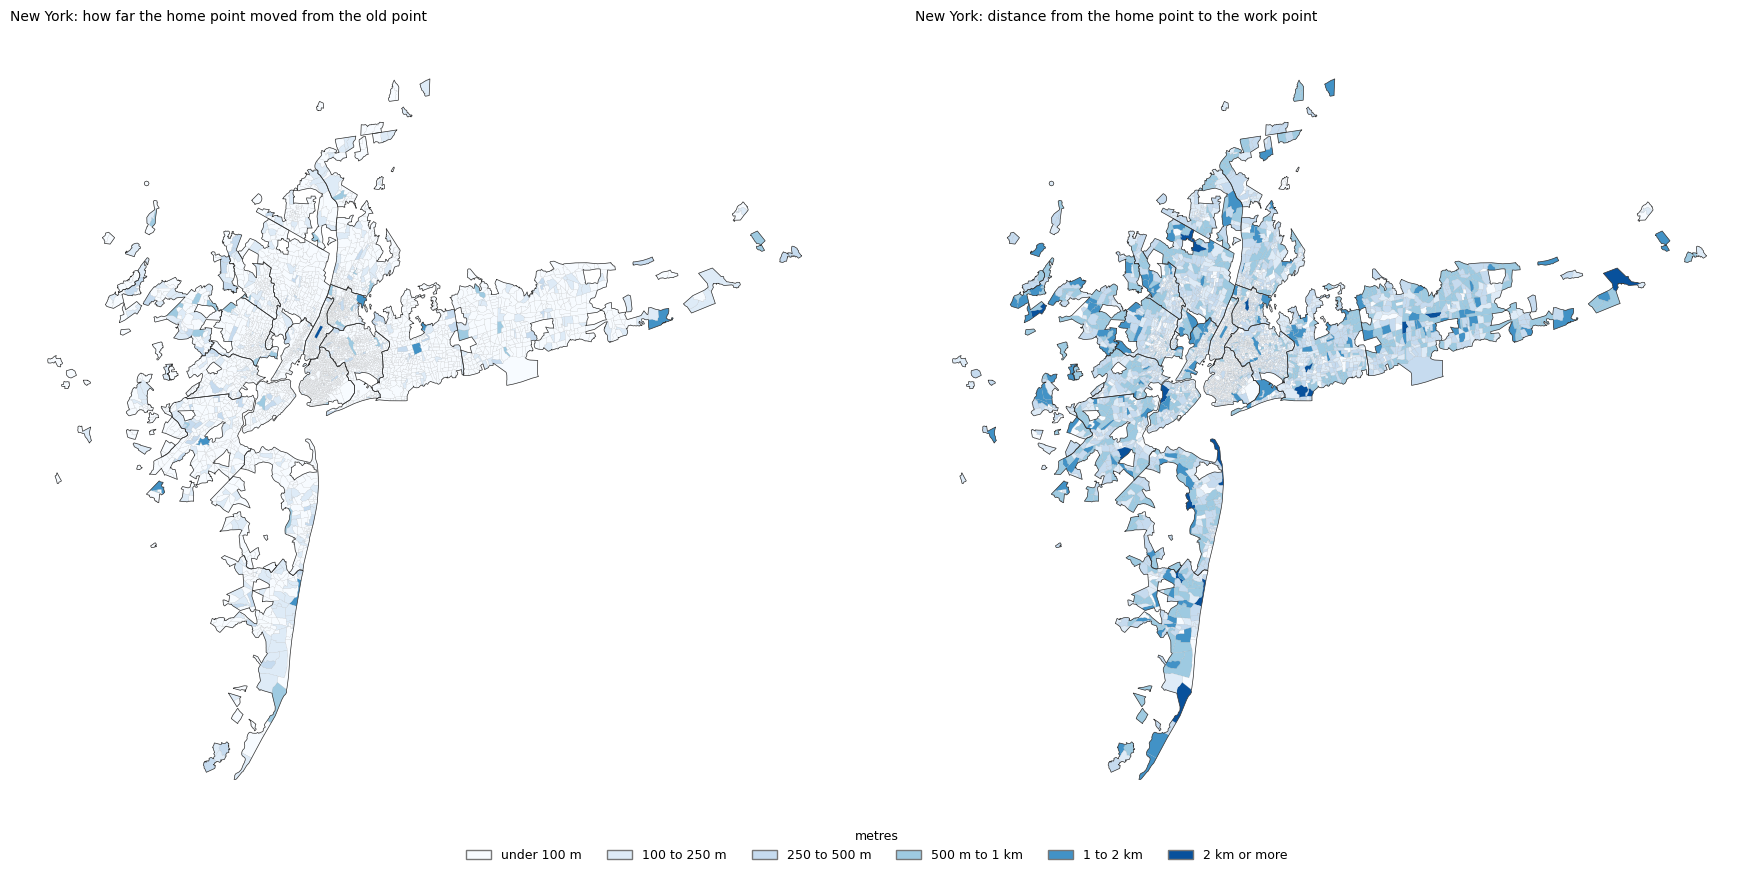

In [5]:
DISTANCE_BINS = [0, 100, 250, 500, 1000, 2000, np.inf]
DISTANCE_COLOURS = ["#f7fbff", "#deebf7", "#c6dbef", "#9ecae1", "#4292c6", "#08519c"]
DISTANCE_LABELS = ["under 100 m", "100 to 250 m", "250 to 500 m", "500 m to 1 km", "1 to 2 km", "2 km or more"]
MISSING_COLOUR = "#d9d9d9"


def class_colours(values, bins, colours):
    index = pd.cut(values, bins, right=False, labels=False)
    return [MISSING_COLOUR if np.isnan(i) else colours[int(i)] for i in index]


def distance_map(area):
    spec = AREAS[area]
    shown = tracts[area][["tract", "NAMELSADCO", "geometry"]].to_crs(spec["metric_crs"])
    shown = shown.merge(home_points[area][["tract", "old_to_home_m"]], on="tract").merge(work_points[area][["tract", "home_to_work_m"]], on="tract")
    counties = shown.dissolve("NAMELSADCO").boundary
    figure, axes = plt.subplots(ncols=2, figsize=(18, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    for axis, column, title in zip(axes, ["old_to_home_m", "home_to_work_m"],
                                   ["how far the home point moved from the old point", "distance from the home point to the work point"]):
        shown.plot(ax=axis, color=class_colours(shown[column], DISTANCE_BINS, DISTANCE_COLOURS), edgecolor="#9a9a9a", linewidth=0.08)
        counties.plot(ax=axis, color="#333333", linewidth=0.5)
        axis.set_title(f"{area}: {title}", loc="left", fontsize=10)
        axis.set_aspect("equal")
        axis.set_axis_off()
    handles = [Patch(facecolor=colour, edgecolor="#777777", label=label) for colour, label in zip(DISTANCE_COLOURS, DISTANCE_LABELS)]
    figure.legend(handles=handles, loc="outside lower center", ncol=6, frameon=False, title="metres", fontsize=9, title_fontsize=9)
    return figure


distance_map("New York");


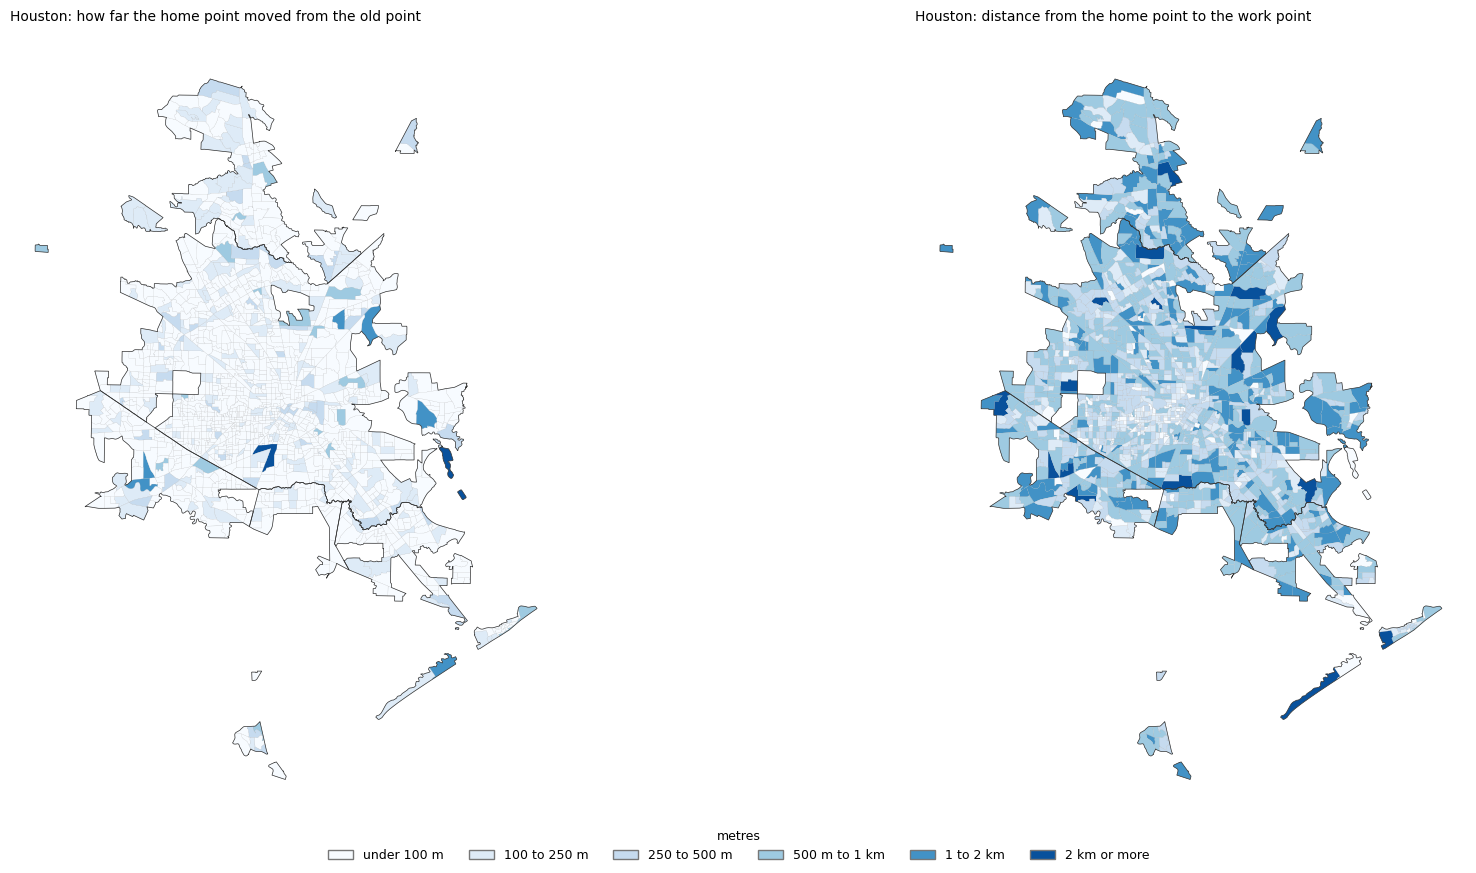

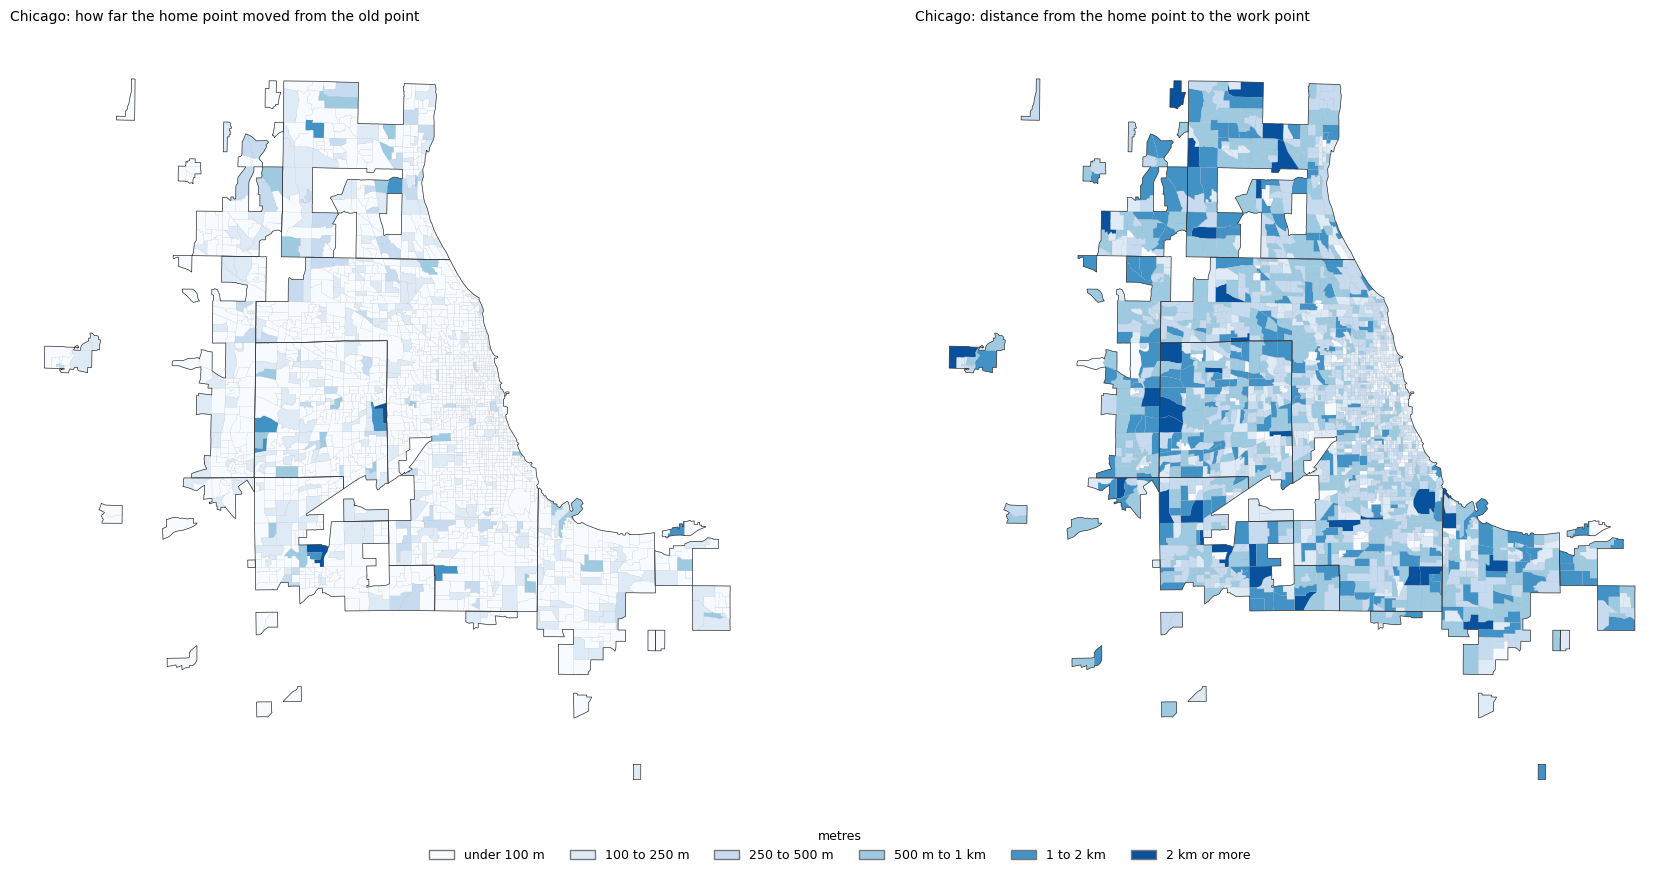

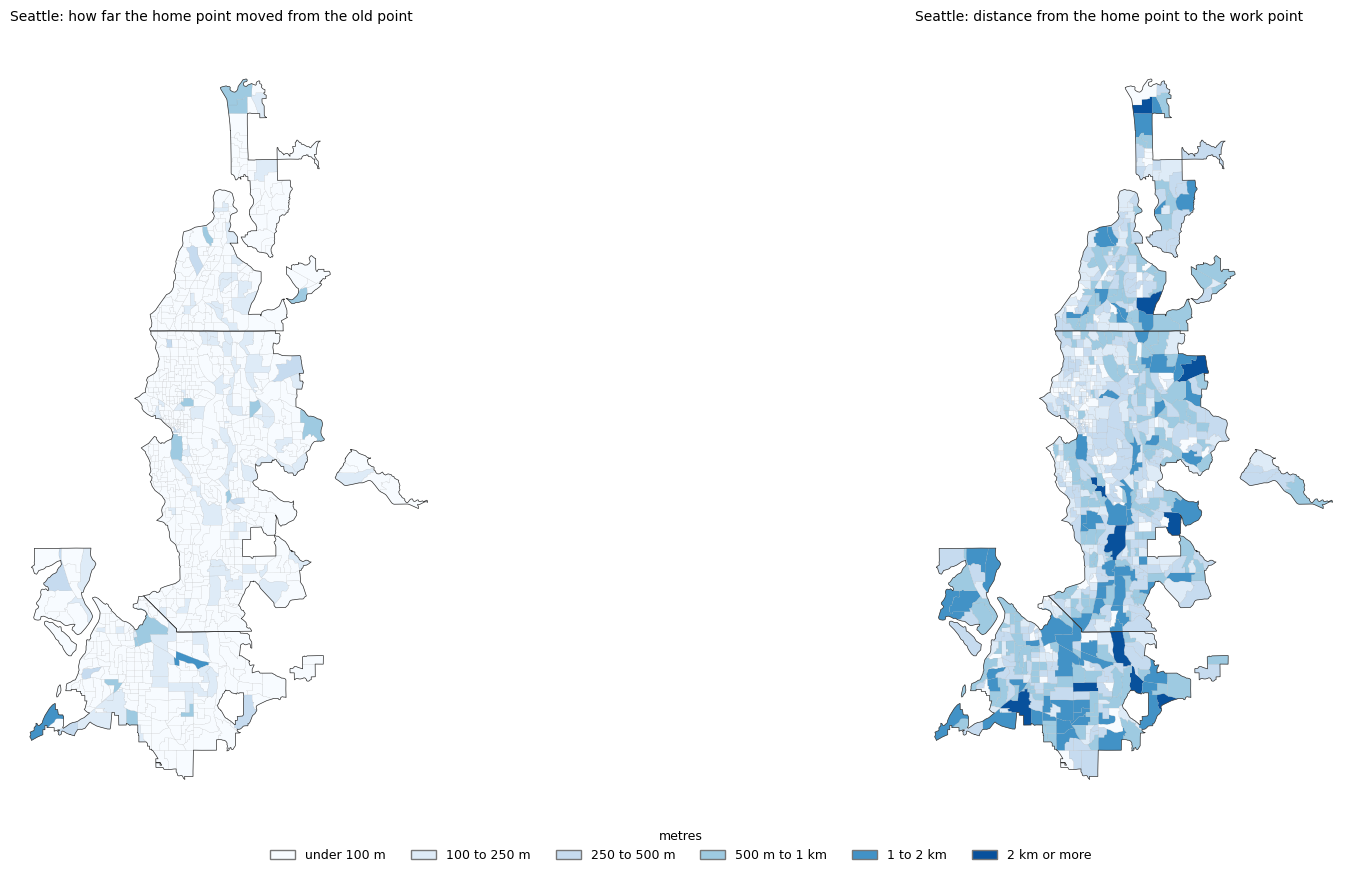

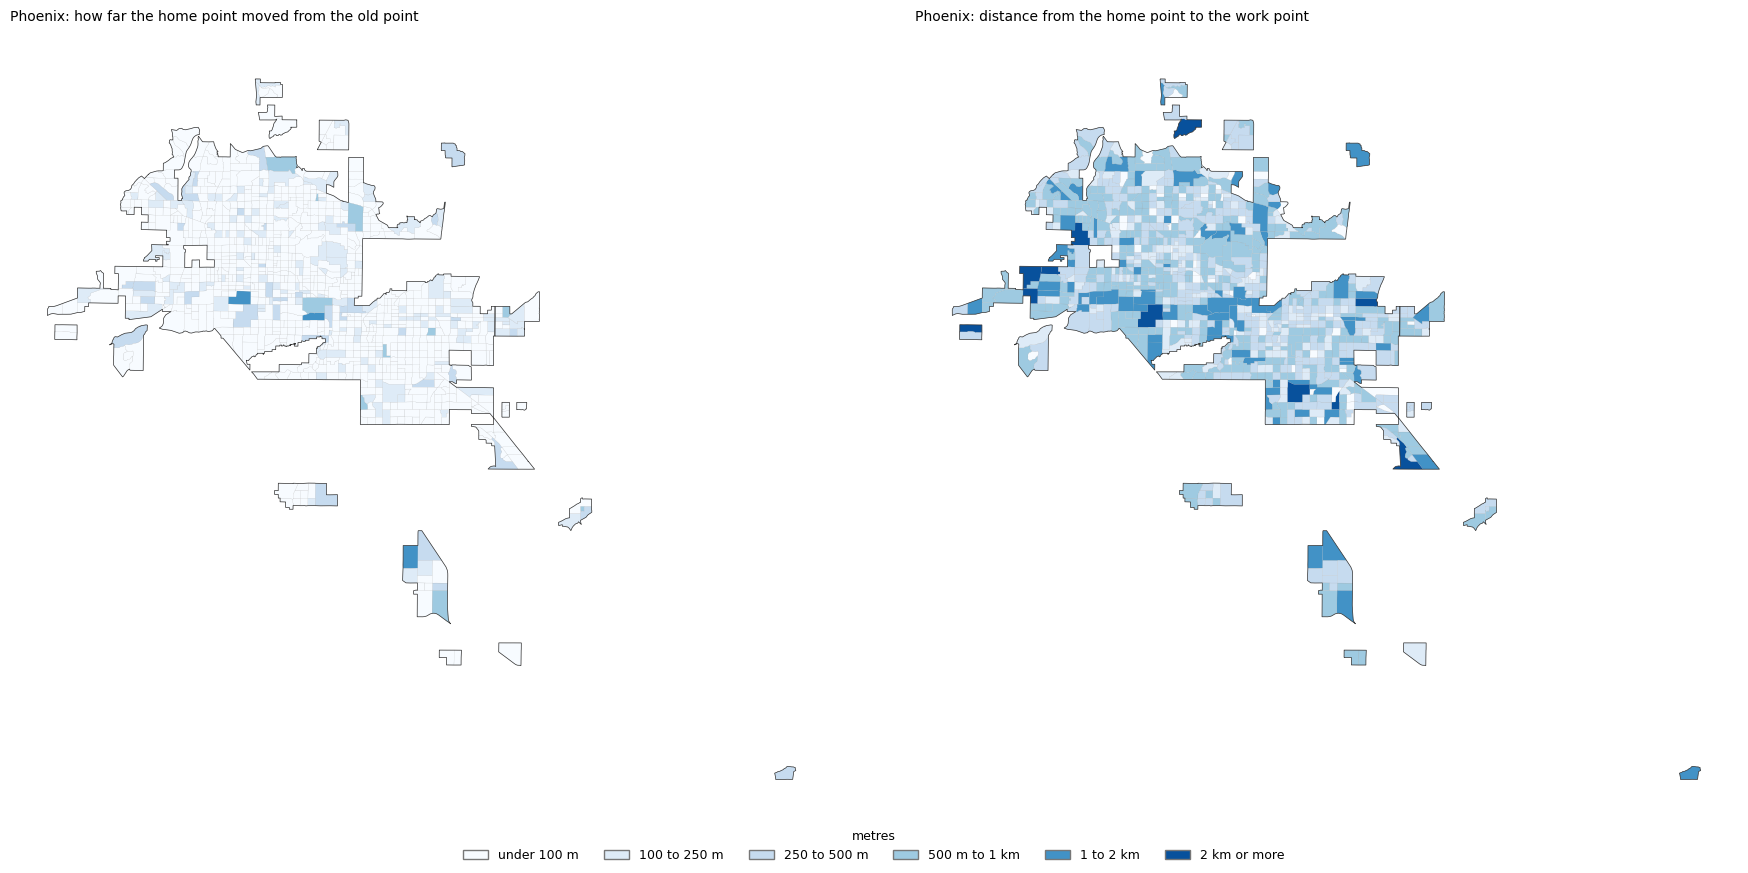

In [6]:
distance_map("Houston");
distance_map("Chicago");
distance_map("Seattle");
distance_map("Phoenix");


## 2b. The switched tracts

How often the weighted mean fell on an empty block and was replaced by the medoid, per area
and per point, with the share of residents and jobs in those tracts and how far their mean sat
from the medoid against the other tracts. The maps show where the switched tracts are, home
points on the left and work points on the right. No mean fell outside every block, so none was
in water.


weighted means that fell on a block with no housing (home) or no jobs (work) and were replaced by the medoid:


area                                            New York             Houston  \
point                                               home      work      home   
tracts with a weighted mean                     4552.000  4567.000  1444.000   
mean on an empty block, replaced by the medoid   165.000   750.000    69.000   
share of tracts                                    0.036     0.164     0.048   
share of residents                                 0.034       NaN     0.050   
mean to medoid, median m, switched tracts        135.636   162.755   255.186   
mean to medoid, median m, other tracts            77.098    95.883   147.747   
switched tracts with mean to medoid over 500 m     9.000    47.000    15.000   
other tracts with mean to medoid over 500 m       44.000   143.000    78.000   
share of jobs                                        NaN     0.092       NaN   

area                                                       Chicago            \
point                                               work      home      work   
tracts with a weighted mean                     1444.000  2150.000  2147.000   
mean on an empty block, replaced by the medoid   362.000   157.000   771.000   
share of tracts                                    0.251     0.073     0.359   
share of residents                                   NaN     0.072       NaN   
mean to medoid, median m, switched tracts        315.415   184.337   211.788   
mean to medoid, median m, other tracts           236.368    89.316   162.159   
switched tracts with mean to medoid over 500 m    74.000    23.000    77.000   
other tracts with mean to medoid over 500 m      173.000    49.000   135.000   
share of jobs                                      0.160       NaN     0.183   

area                                            Seattle            Phoenix  \
point                                              home     work      home   
tracts with a weighted mean                     791.000  791.000  1002.000   
mean on an empty block, replaced by the medoid   44.000  149.000    51.000   
share of tracts                                   0.056    0.188     0.051   
share of residents                                0.053      NaN     0.051   
mean to medoid, median m, switched tracts       193.691  280.919   199.426   
mean to medoid, median m, other tracts          131.069  215.437   124.869   
switched tracts with mean to medoid over 500 m    9.000   25.000     5.000   
other tracts with mean to medoid over 500 m      27.000   74.000    20.000   
share of jobs                                       NaN    0.086       NaN   

area                                                      
point                                               work  
tracts with a weighted mean                     1008.000  
mean on an empty block, replaced by the medoid   288.000  
share of tracts                                    0.286  
share of residents                                   NaN  
mean to medoid, median m, switched tracts        302.164  
mean to medoid, median m, other tracts           246.438  
switched tracts with mean to medoid over 500 m    50.000  
other tracts with mean to medoid over 500 m       91.000  
share of jobs                                      0.149

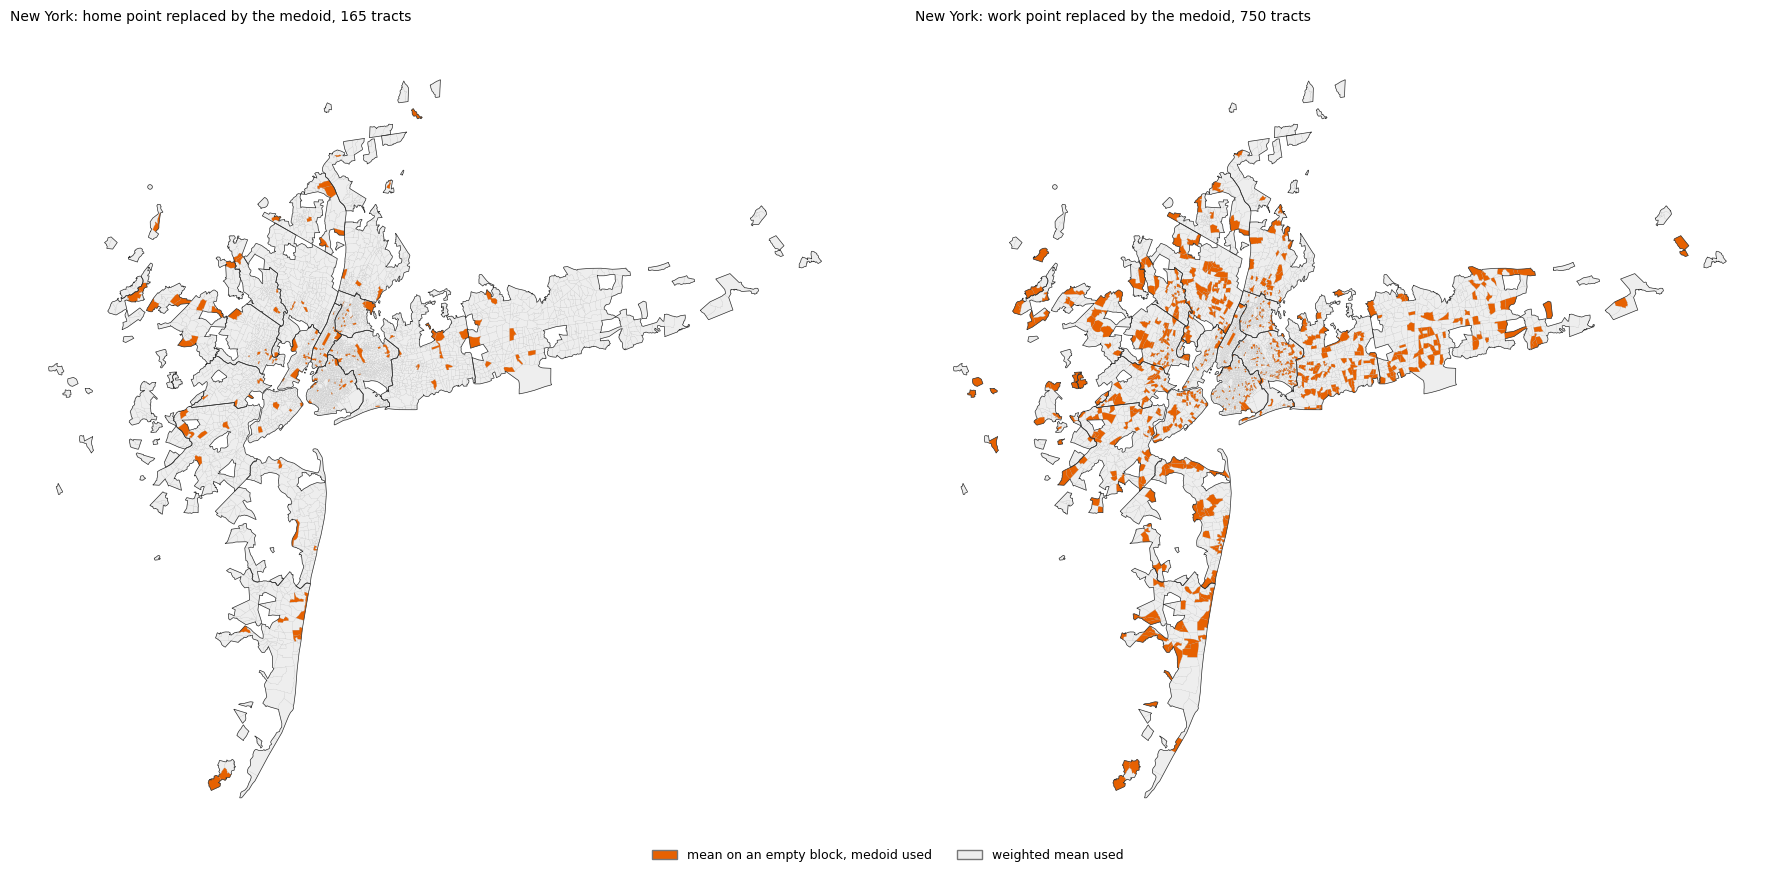

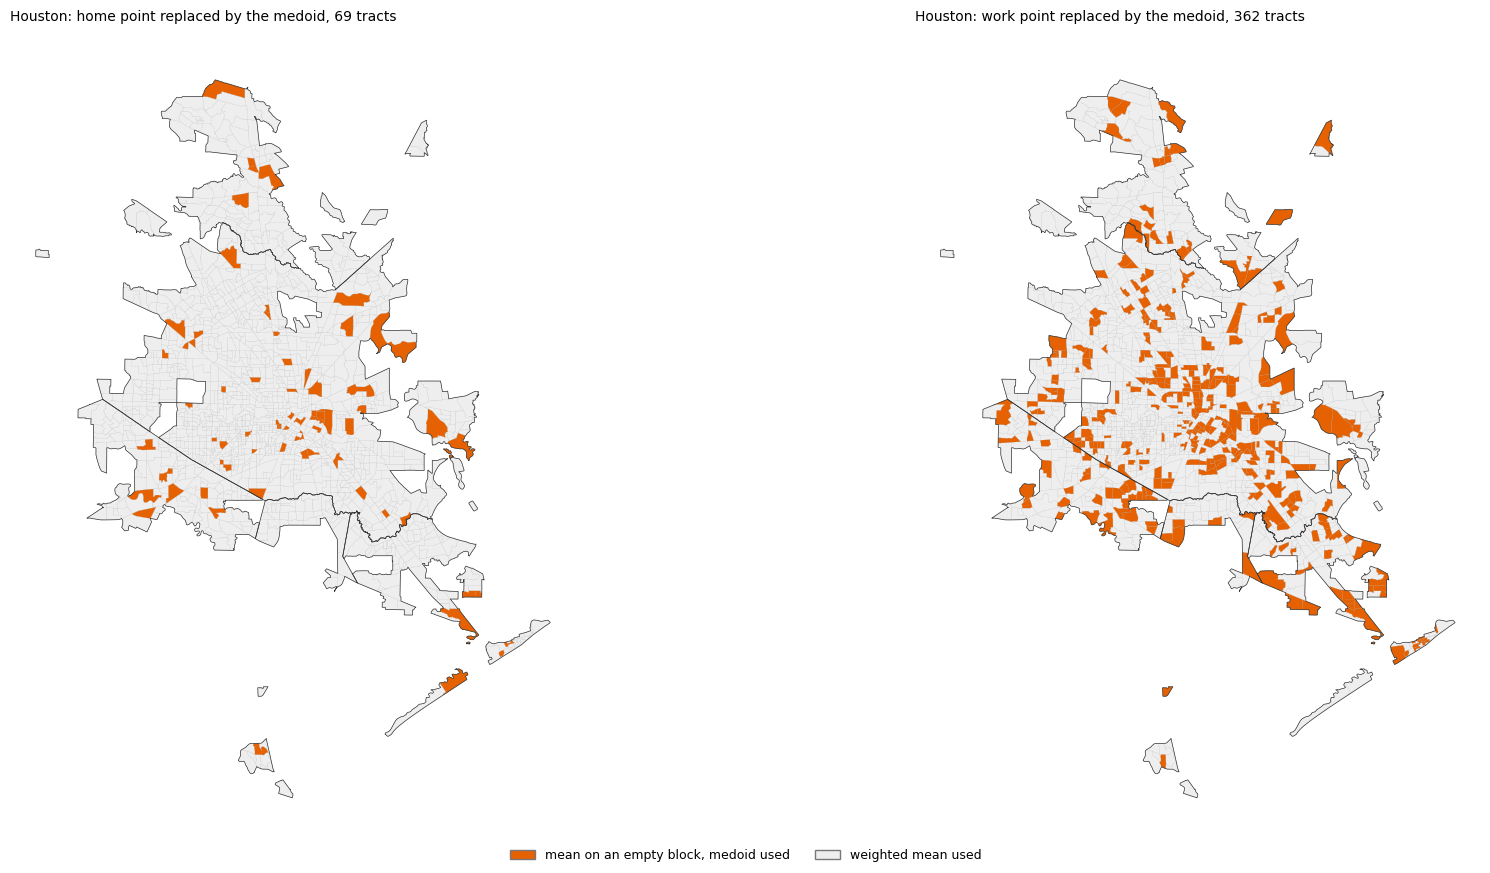

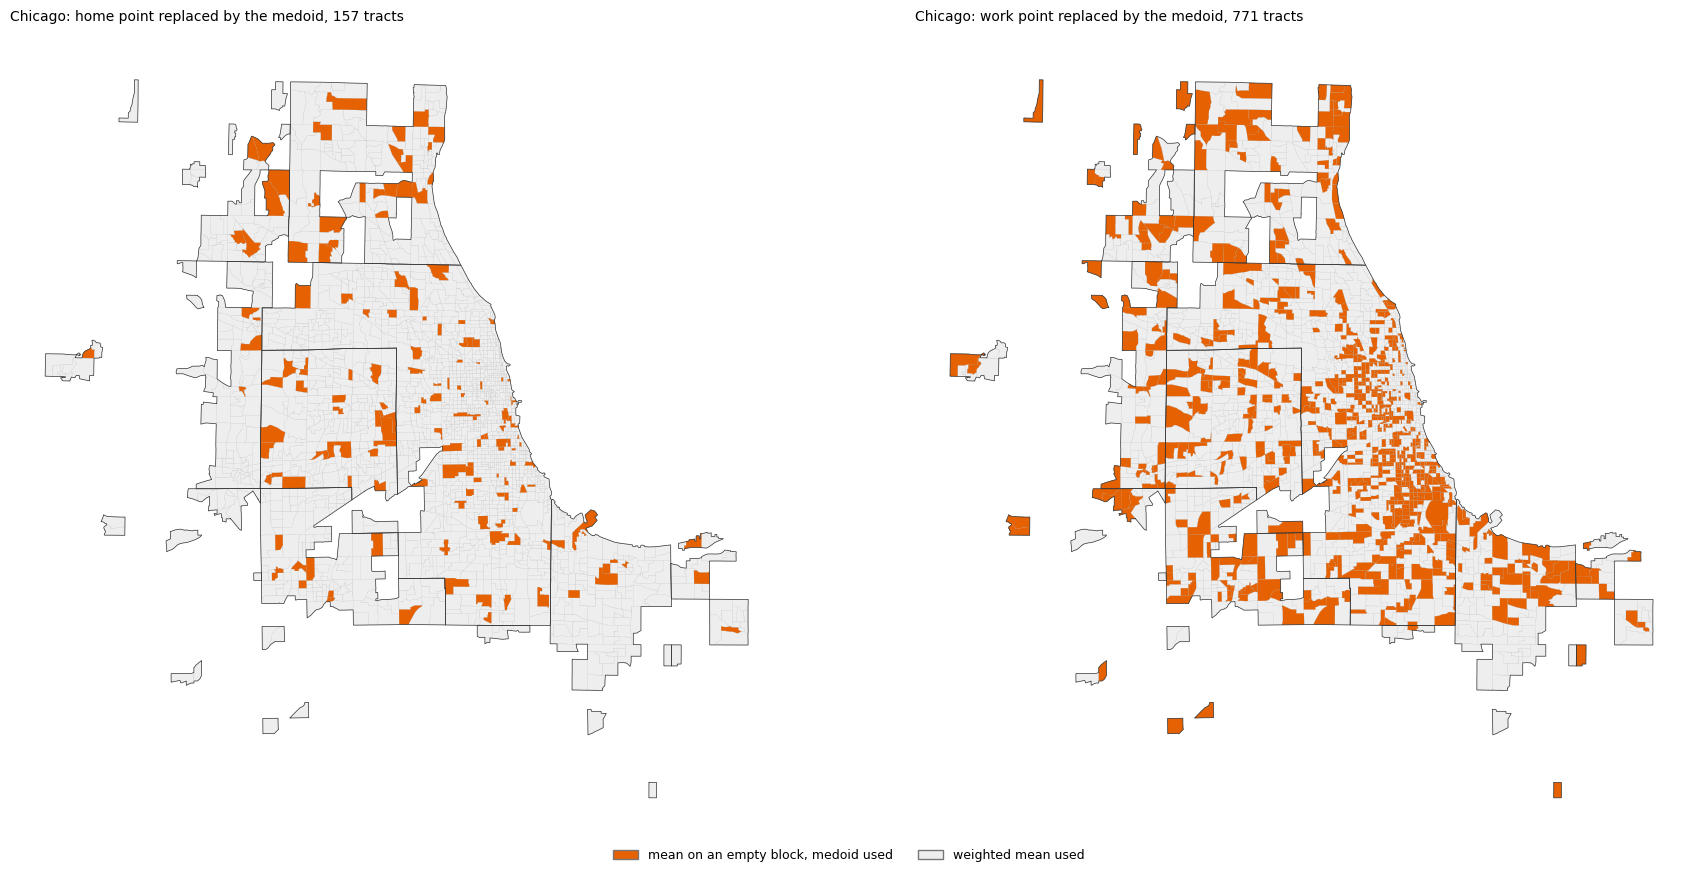

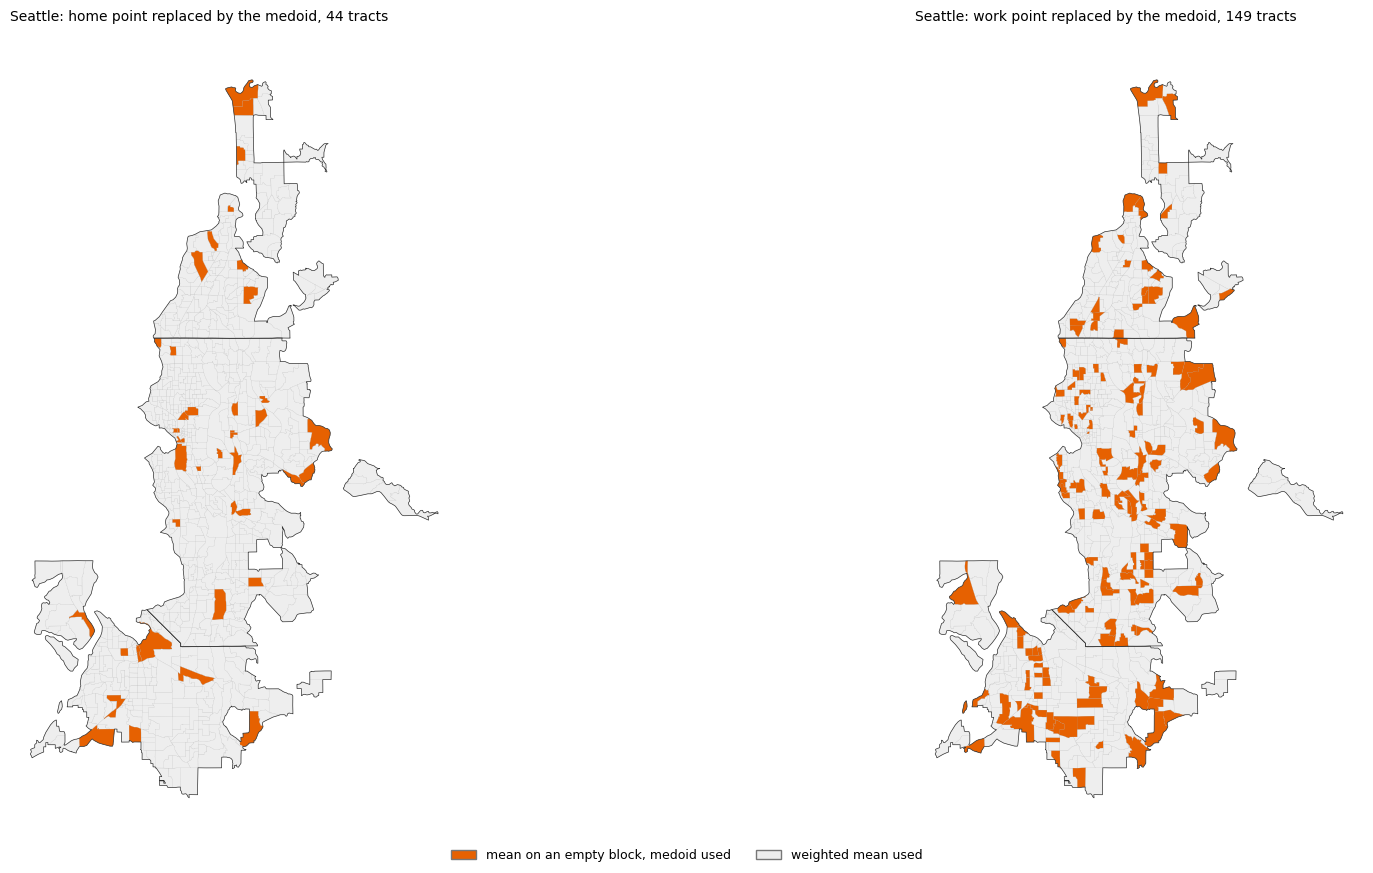

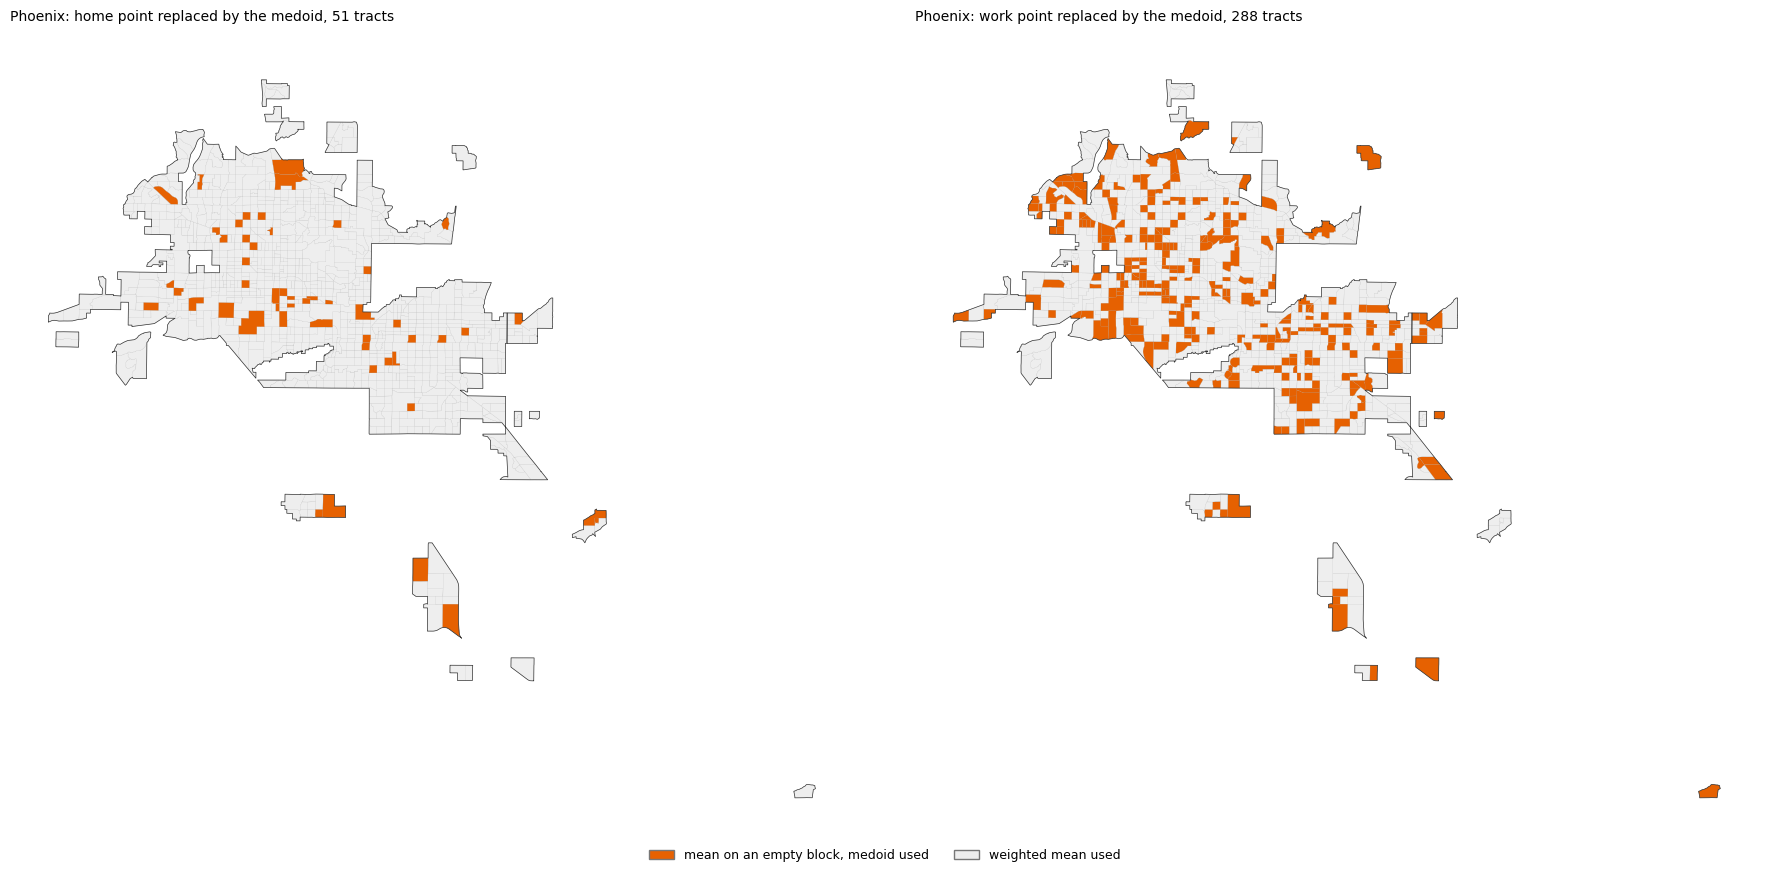

In [7]:
rows = []
for area in AREAS:
    workers = tracts[area].set_index("tract")[["workers_home", "workers_work"]]
    for name, points, share_column in (("home", home_points[area], "workers_home"), ("work", work_points[area], "workers_work")):
        measured = points.loc[points["mean_to_medoid_m"].notna()].copy()
        measured["workers"] = workers.loc[measured["tract"], share_column].to_numpy()
        switched = measured.loc[measured["mean_on_empty_block"]]
        rows.append({
            "area": area, "point": name,
            "tracts with a weighted mean": len(measured),
            "mean on an empty block, replaced by the medoid": len(switched),
            "share of tracts": len(switched) / len(measured),
            f"share of {'residents' if name == 'home' else 'jobs'}": switched["workers"].sum() / measured["workers"].sum(),
            "mean to medoid, median m, switched tracts": switched["mean_to_medoid_m"].median(),
            "mean to medoid, median m, other tracts": measured.loc[~measured["mean_on_empty_block"], "mean_to_medoid_m"].median(),
            "switched tracts with mean to medoid over 500 m": int((switched["mean_to_medoid_m"] > 500).sum()),
            "other tracts with mean to medoid over 500 m": int((measured.loc[~measured["mean_on_empty_block"], "mean_to_medoid_m"] > 500).sum()),
        })
print("weighted means that fell on a block with no housing (home) or no jobs (work) and were replaced by the medoid:")
display(pd.DataFrame(rows).set_index(["area", "point"]).T.round(3))


def switch_map(area):
    spec = AREAS[area]
    shown = tracts[area][["tract", "NAMELSADCO", "geometry"]].to_crs(spec["metric_crs"])
    counties = shown.dissolve("NAMELSADCO").boundary
    figure, axes = plt.subplots(ncols=2, figsize=(18, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    for axis, points, title in zip(axes, [home_points[area], work_points[area]], ["home point", "work point"]):
        switched = points.loc[points["mean_on_empty_block"], "tract"]
        shown.plot(ax=axis, color="#eeeeee", edgecolor="#9a9a9a", linewidth=0.08)
        shown.loc[shown["tract"].isin(switched)].plot(ax=axis, color="#e66101", edgecolor="#9a9a9a", linewidth=0.08)
        counties.plot(ax=axis, color="#333333", linewidth=0.5)
        axis.set_title(f"{area}: {title} replaced by the medoid, {len(switched)} tracts", loc="left", fontsize=10)
        axis.set_aspect("equal")
        axis.set_axis_off()
    figure.legend(handles=[Patch(facecolor="#e66101", edgecolor="#777777", label="mean on an empty block, medoid used"),
                           Patch(facecolor="#eeeeee", edgecolor="#777777", label="weighted mean used")],
                  loc="outside lower center", ncol=2, frameon=False, fontsize=9)
    return figure


switch_map("New York");
switch_map("Houston");
switch_map("Chicago");
switch_map("Seattle");
switch_map("Phoenix");


## 3. Snapping

Routing starts and ends on a street, so both points are moved to one with the rule of 05.3: the
nearest point of a street edge of the cafein network that lies inside the tract, at most
1,000 m away, every edge counting as a street whatever modes may use it. A tract with no street
inside its polygon within that distance gets no point and its flows are dropped, as before. The
street networks are the artifacts saved by 05.3 and 05.3.1. The edges of each tract are cut out
once and both points of the tract are snapped to the same cut, so the work is done once per
tract. The snapped points are saved as two files per area, with the tract code as id, in the
same form as the file 05.3 routed from.


In [8]:
from shapely.ops import nearest_points

from cafein import StreetNetwork

SNAP_DISTANCE_M = 1000
STREET_ARTIFACTS = {"New York": Path("../networks/new-york-streets.cafein"), "Houston": RESULTS / "houston" / "houston-streets.cafein", "Chicago": RESULTS / "chicago" / "chicago-streets.cafein", "Seattle": RESULTS / "seattle" / "seattle-streets.cafein", "Phoenix": RESULTS / "phoenix" / "phoenix-streets.cafein"}


def snap_points(area):
    # Both points of every kept tract moved to the nearest street inside the tract, in the metric CRS.
    spec = AREAS[area]
    started = time.time()
    streets = StreetNetwork.load(STREET_ARTIFACTS[area])
    edges = streets.streets_gdf[["geometry"]].to_crs(spec["metric_crs"])
    polygons = tracts[area][["tract", "geometry"]].to_crs(spec["metric_crs"])
    print(f"{area}: {len(edges):,} edges loaded, {time.time() - started:.0f} s")
    # Which edges touch which tract (an edge crossing a border appears in both tracts), grouped once per tract.
    edges_in_tracts = gpd.sjoin(edges, polygons, how="inner", predicate="intersects")
    edges_by_tract = {tract: group for tract, group in edges_in_tracts.groupby("tract")["geometry"]}
    print(f"{area}: {len(edges_in_tracts):,} edge-tract matches, {time.time() - started:.0f} s")
    home = home_points[area].set_index("tract").geometry
    work = work_points[area].set_index("tract").geometry
    rows = []
    for tract, polygon in polygons.itertuples(index=False):
        row = {"tract": tract, "home_snap_m": np.nan, "home_snapped": None, "work_snap_m": np.nan, "work_snapped": None}
        if tract in edges_by_tract:
            # Keep only the parts of the edges that lie inside the tract, then take the closest point for each point.
            streets_inside = edges_by_tract[tract].intersection(polygon).union_all()
            for name, point in (("home", home[tract]), ("work", work[tract])):
                snapped = nearest_points(point, streets_inside)[1]
                row[f"{name}_snap_m"] = point.distance(snapped)
                row[f"{name}_snapped"] = snapped
        rows.append(row)
    print(f"{area}: snapping done, {time.time() - started:.0f} s")
    return pd.DataFrame(rows)


snapped = {}
for area, spec in AREAS.items():
    snapped[area] = snap_points(area)
    table = snapped[area]
    print(f"{area}: {len(table):,} tracts; {table['home_snap_m'].isna().sum()} with no street inside at all")
    for name in ("home", "work"):
        within = table[f"{name}_snap_m"] <= SNAP_DISTANCE_M
        routing = gpd.GeoDataFrame({"id": table.loc[within, "tract"].to_numpy()}, geometry=table.loc[within, f"{name}_snapped"].to_numpy(),
                                   crs=spec["metric_crs"]).to_crs("EPSG:4326")
        routing.to_parquet(spec["folder"] / f"tract-points-{name}-snapped-{YEAR}.parquet", index=False)
        print(f"{area}: {name} point, {(~within).sum()} tracts left without a point under the {SNAP_DISTANCE_M} m rule, {len(routing):,} points saved")
    print(f"{area}: distance from the point to its snapped point (m):")
    display(table[["home_snap_m", "work_snap_m"]].describe(percentiles=[0.5, 0.9, 0.99]).round(0).T)
    dropped = table.loc[(table["home_snap_m"] > SNAP_DISTANCE_M) | (table["work_snap_m"] > SNAP_DISTANCE_M) | table["home_snap_m"].isna()]
    if len(dropped):
        print(f"{area}: tracts left without a routable point:")
        display(dropped[["tract", "home_snap_m", "work_snap_m"]].merge(tracts[area][["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work"]], on="tract").round(0))


New York: 12,634,812 edges loaded, 104 s


New York: 5,958,223 edge-tract matches, 114 s


New York: snapping done, 163 s
New York: 4,589 tracts; 0 with no street inside at all


New York: home point, 2 tracts left without a point under the 1000 m rule, 4,587 points saved
New York: work point, 1 tracts left without a point under the 1000 m rule, 4,588 points saved
New York: distance from the point to its snapped point (m):


,count,mean,std,min,50%,90%,99%,max
home_snap_m,4589.0,18.0,35.0,0.0,12.0,36.0,103.0,1171.0
work_snap_m,4589.0,19.0,29.0,0.0,13.0,39.0,110.0,1171.0


New York: tracts left without a routable point:


... (19 outputs left out)

Phoenix: 3,432,727 edge-tract matches, 42 s


Phoenix: snapping done, 67 s


Phoenix: 1,008 tracts; 0 with no street inside at all
Phoenix: home point, 0 tracts left without a point under the 1000 m rule, 1,008 points saved
Phoenix: work point, 0 tracts left without a point under the 1000 m rule, 1,008 points saved
Phoenix: distance from the point to its snapped point (m):


,count,mean,std,min,50%,90%,99%,max
home_snap_m,1008.0,20.0,26.0,0.0,14.0,40.0,105.0,443.0
work_snap_m,1008.0,21.0,27.0,0.0,15.0,43.0,103.0,554.0


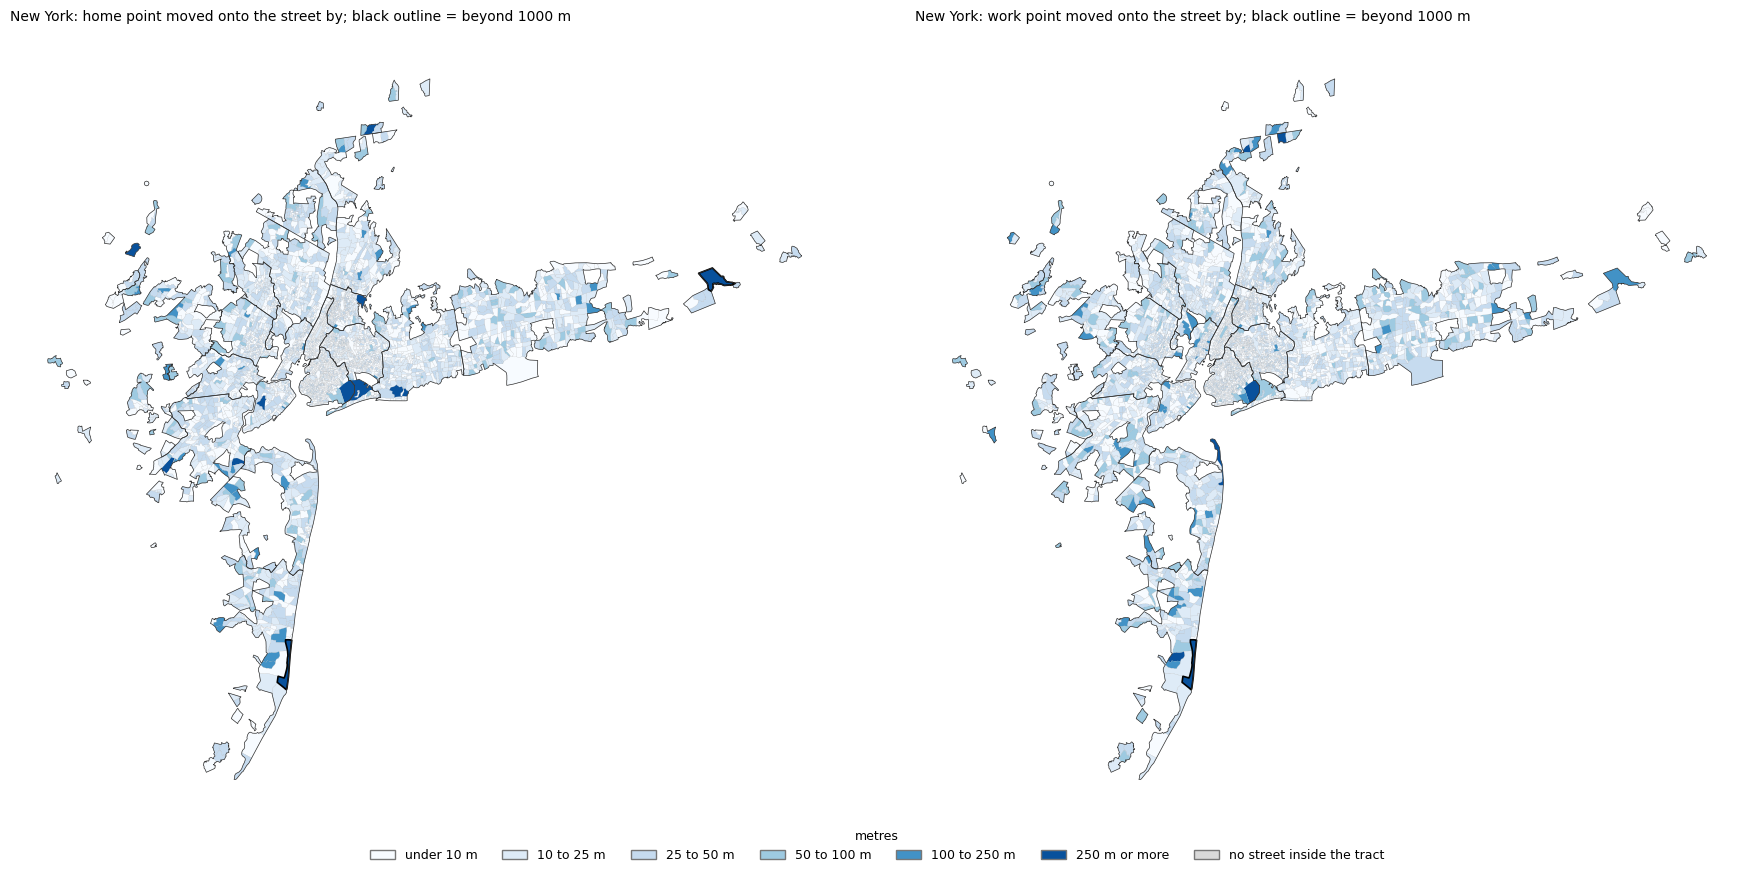

In [9]:
SNAP_BINS = [0, 10, 25, 50, 100, 250, np.inf]
SNAP_LABELS = ["under 10 m", "10 to 25 m", "25 to 50 m", "50 to 100 m", "100 to 250 m", "250 m or more"]


def snap_map(area):
    spec = AREAS[area]
    shown = tracts[area][["tract", "NAMELSADCO", "geometry"]].to_crs(spec["metric_crs"]).merge(snapped[area][["tract", "home_snap_m", "work_snap_m"]], on="tract")
    counties = shown.dissolve("NAMELSADCO").boundary
    figure, axes = plt.subplots(ncols=2, figsize=(18, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    for axis, column, title in zip(axes, ["home_snap_m", "work_snap_m"], ["home point moved onto the street by", "work point moved onto the street by"]):
        shown.plot(ax=axis, color=class_colours(shown[column], SNAP_BINS, DISTANCE_COLOURS), edgecolor="#9a9a9a", linewidth=0.08)
        counties.plot(ax=axis, color="#333333", linewidth=0.5)
        shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)
        axis.set_title(f"{area}: {title}; black outline = beyond {SNAP_DISTANCE_M} m", loc="left", fontsize=10)
        axis.set_aspect("equal")
        axis.set_axis_off()
    handles = [Patch(facecolor=colour, edgecolor="#777777", label=label) for colour, label in zip(DISTANCE_COLOURS, SNAP_LABELS)]
    handles.append(Patch(facecolor=MISSING_COLOUR, edgecolor="#777777", label="no street inside the tract"))
    figure.legend(handles=handles, loc="outside lower center", ncol=7, frameon=False, title="metres", fontsize=9, title_fontsize=9)
    return figure


snap_map("New York");


/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)


/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)


/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)
/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)


/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)
/tmp/marinflo/3373257/ipykernel_2163713/1713201744.py:14: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  shown.loc[shown[column] > SNAP_DISTANCE_M].plot(ax=axis, facecolor="none", edgecolor="black", linewidth=1.2)


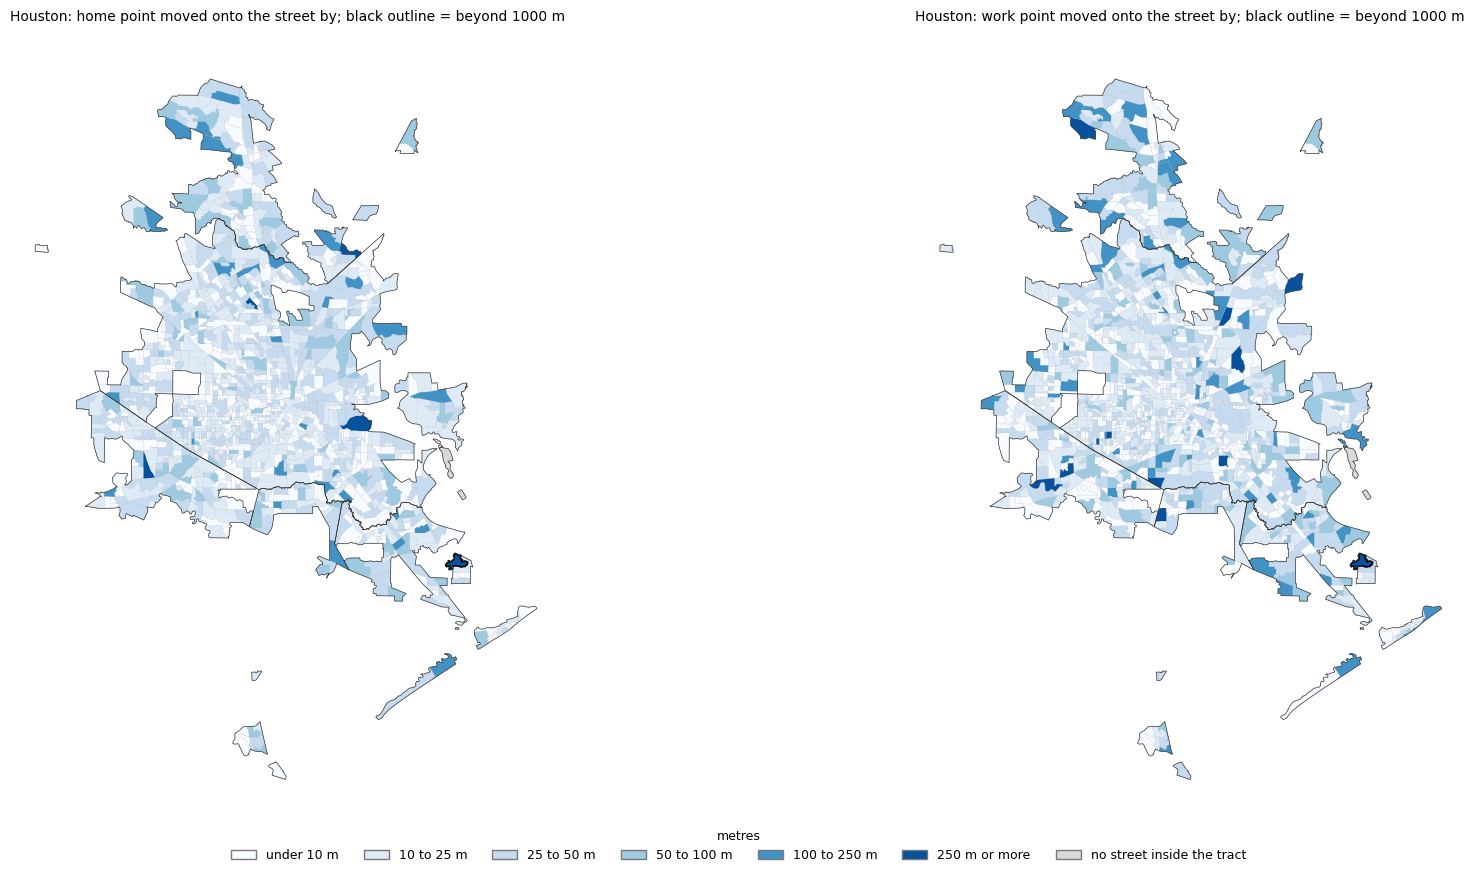

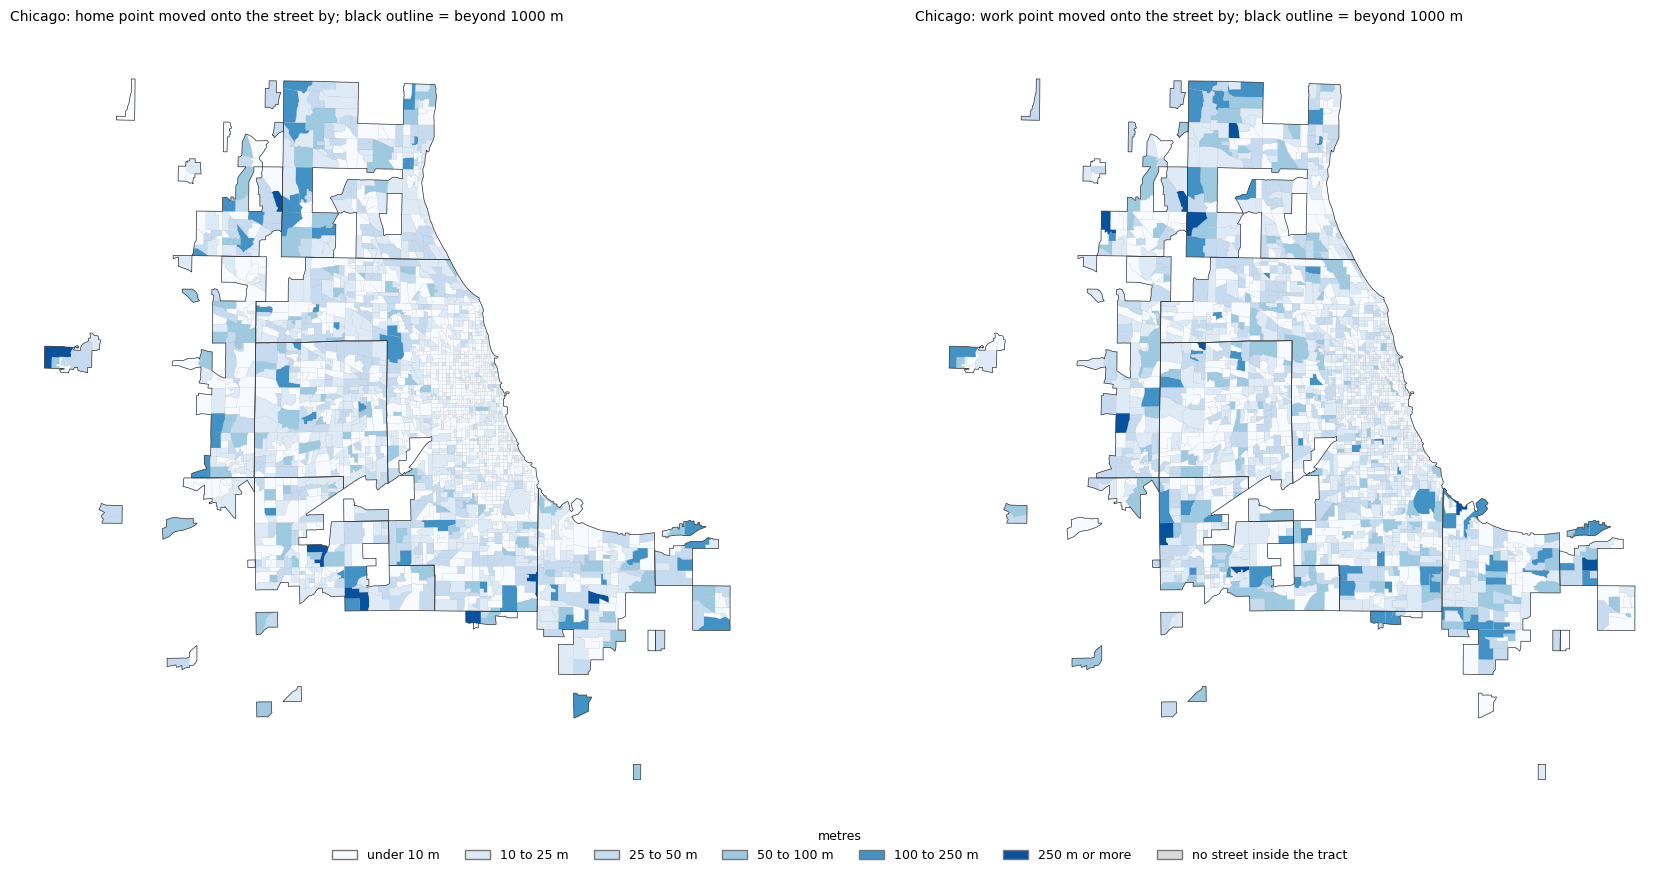

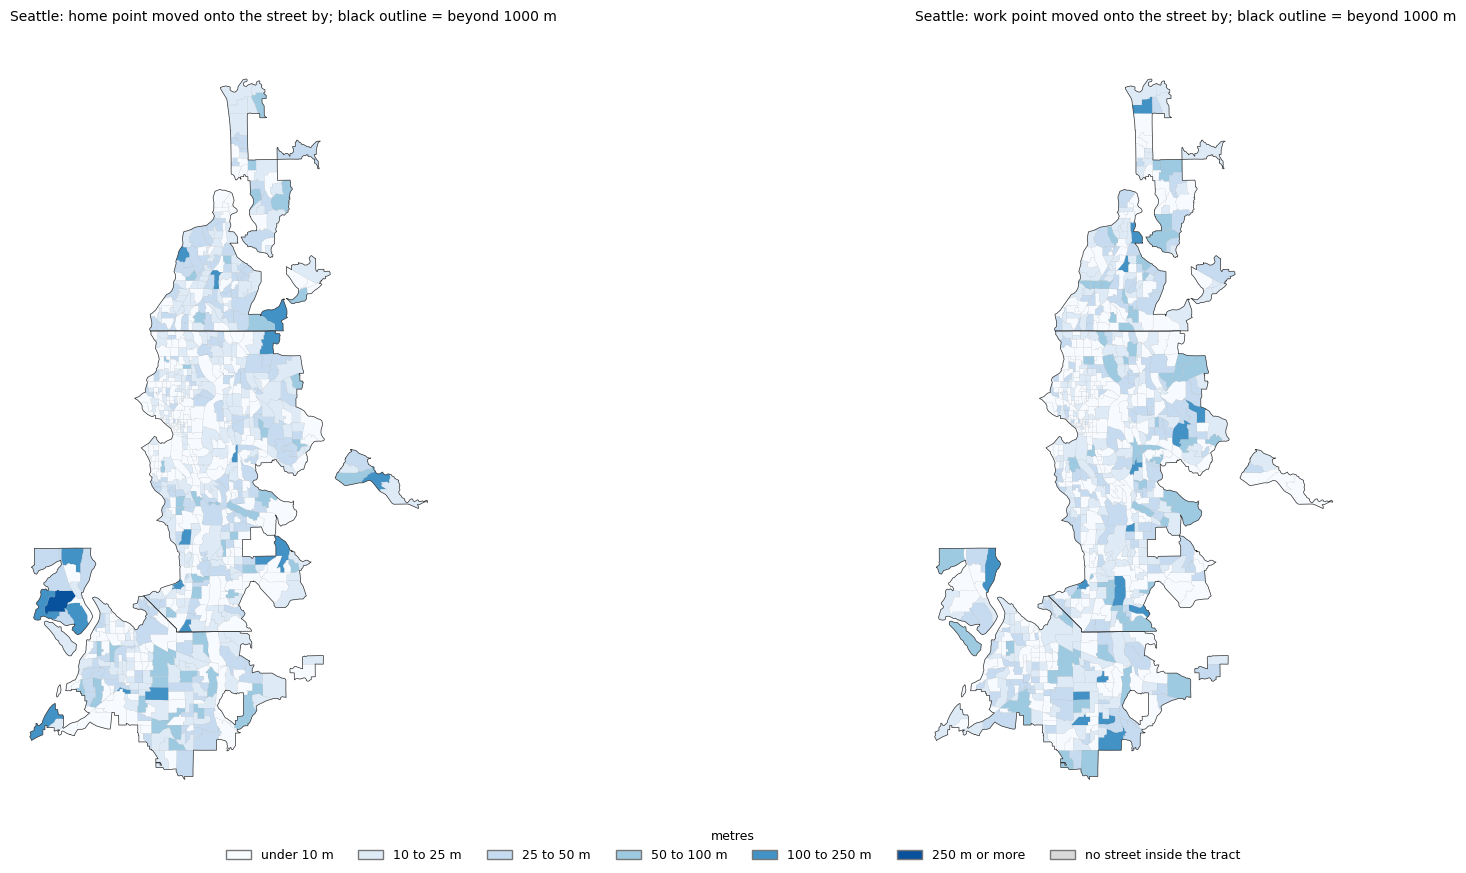

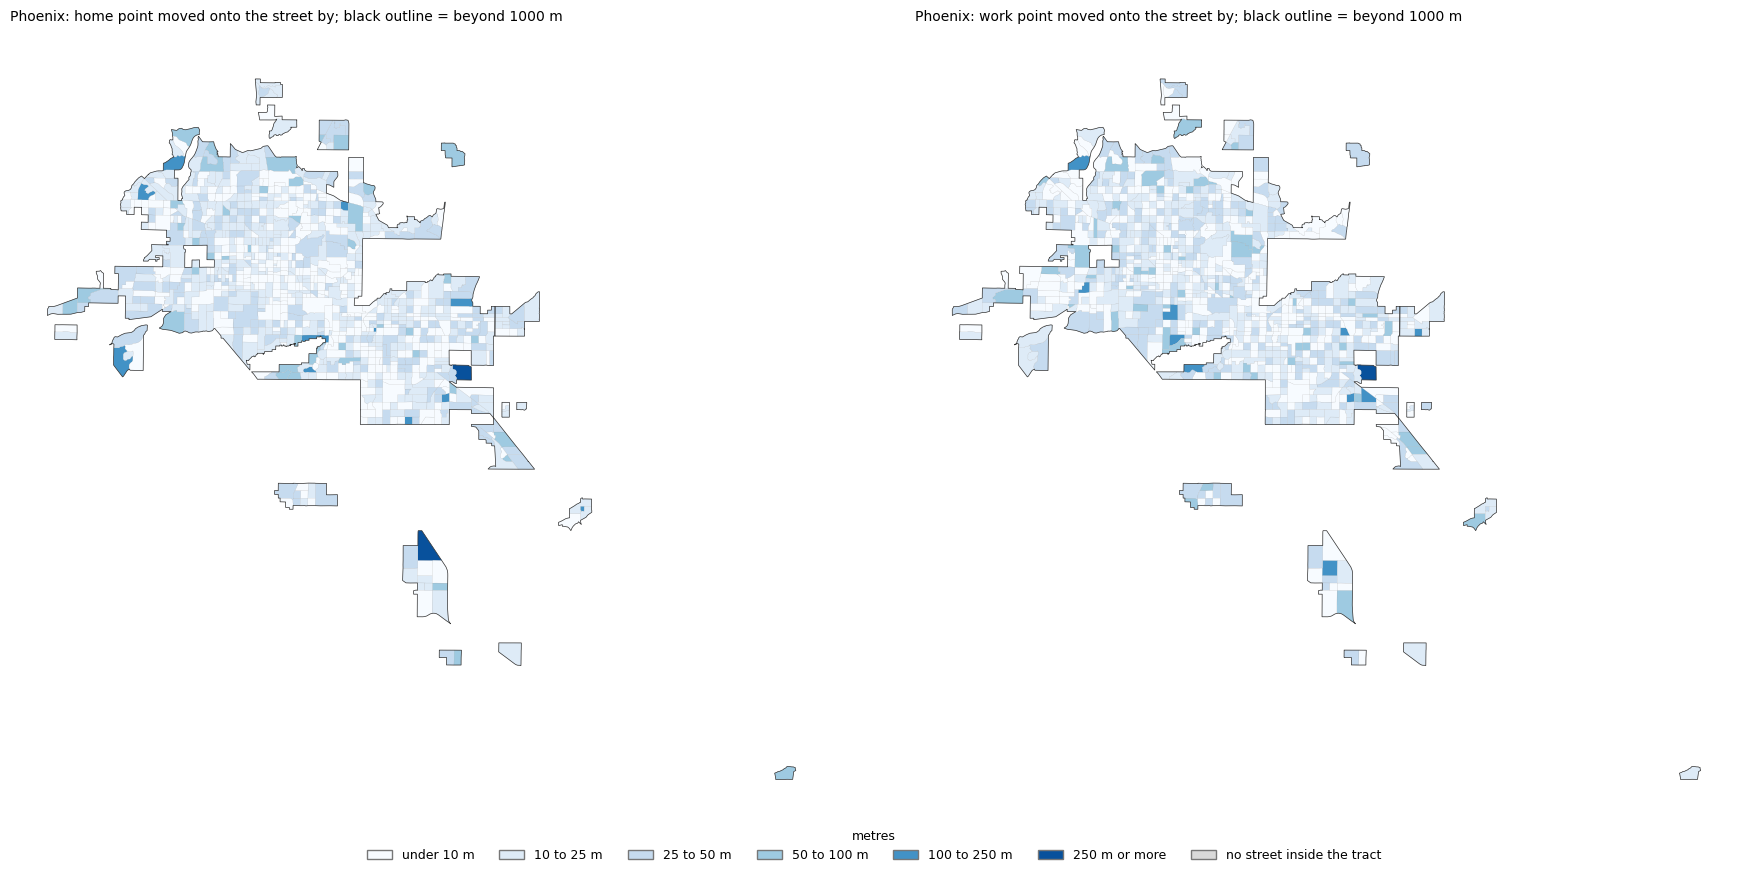

In [10]:
snap_map("Houston");
snap_map("Chicago");
snap_map("Seattle");
snap_map("Phoenix");


## 4. Transit routing from home points to work points, against 05.3

The transit matrix of each area is computed again, from the snapped home points to the snapped
work points, at the departure of 05.3, Tuesday 2026-11-10 at 08:30, on the transit networks
05.3 and 05.3.1 saved. It is streamed to a folder of its own beside the 05.3 matrices, so the
old results stay as they are. The commuting flows are then joined to both results: the new
one, and the 05.3 one that routed one resident-weighted point at both ends of every commute.

Two things differ by construction. A commute inside one tract had zero minutes in 05.3, since
the point routed to itself; it now runs from the tract's home point to its work point and can
be unreached like any other, so within-tract commutes are reported apart. And the tracts
without a routable point are not quite the same: 05.3 dropped one New York tract, the new
points drop two home and one work tract in New York and two of each in Houston, so the
comparison of commutes is made over the pairs that exist in both.


In [11]:
import json

from cafein import TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards

DEPARTURE = "2026-11-10 08:30"
TRANSIT_ARTIFACTS = {"New York": RESULTS / "new-york" / "new-york-transit.cafein", "Houston": RESULTS / "houston" / "houston-transit.cafein", "Chicago": RESULTS / "chicago" / "chicago-transit.cafein", "Seattle": RESULTS / "seattle" / "seattle-transit.cafein", "Phoenix": RESULTS / "phoenix" / "phoenix-transit.cafein"}


def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


two_points = {}
rows = []
for area, spec in AREAS.items():
    origins = gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")
    destinations = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")
    output = spec["folder"] / "matrices-two-points" / "transit"
    if matrix_complete(output):
        print(f"{area}: transit complete -> {output}")
    else:
        started = time.time()
        network = TransportNetwork.load(TRANSIT_ARTIFACTS[area])
        TravelTimeMatrix.to_parquet(network, origins, destinations, output=output, departure=DEPARTURE, output_time_units="seconds", resume=output.exists())
        print(f"{area}: transit {time.time() - started:6.0f} s -> {output}")
    matrix = read_shards(output)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_two_points_min"})
    matrix["transit_two_points_min"] = matrix["transit_two_points_min"] / 60

    flows = pd.read_parquet(spec["folder"] / f"tract-od-{YEAR}.parquet")
    old = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet", columns=["from_id", "to_id", "transit_min"]).rename(columns={"transit_min": "transit_one_point_min"})
    joined = flows.loc[flows["from_id"].isin(origins["id"]) & flows["to_id"].isin(destinations["id"])].merge(matrix, on=["from_id", "to_id"], how="left")
    joined = joined.merge(old.assign(in_05_3=True), on=["from_id", "to_id"], how="left")
    joined["in_05_3"] = joined["in_05_3"].fillna(False).astype(bool)
    joined["within_tract"] = joined["from_id"] == joined["to_id"]
    joined.to_parquet(spec["folder"] / "matrices-two-points" / f"tract-od-transit-{YEAR}.parquet", index=False)
    two_points[area] = joined

    old_all = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet", columns=["from_id", "to_id", "workers", "transit_min"])
    common = joined.loc[joined["in_05_3"] & ~joined["within_tract"]]
    reached_old = common["transit_one_point_min"].notna()
    reached_new = common["transit_two_points_min"].notna()
    both = reached_old & reached_new
    total = common["workers"].sum()
    rows.append({
        "area": area,
        "05.3, one point: commuters with no itinerary, all its pairs": old_all.loc[old_all["transit_min"].isna(), "workers"].sum() / old_all["workers"].sum(),
        "two points: commuters with no itinerary, all its pairs": joined.loc[joined["transit_two_points_min"].isna(), "workers"].sum() / joined["workers"].sum(),
        "two points: of which within-tract commutes": joined.loc[joined["transit_two_points_min"].isna() & joined["within_tract"], "workers"].sum() / joined["workers"].sum(),
        "between-tract pairs in both: commuters": total,
        "  unreached under both": common.loc[~reached_old & ~reached_new, "workers"].sum() / total,
        "  unreached only with one point (gained)": common.loc[~reached_old & reached_new, "workers"].sum() / total,
        "  unreached only with two points (lost)": common.loc[reached_old & ~reached_new, "workers"].sum() / total,
        "  reached under both": common.loc[both, "workers"].sum() / total,
        "  median minutes, one point, reached under both": weighted_median(common.loc[both, "transit_one_point_min"].to_numpy(), common.loc[both, "workers"].to_numpy()),
        "  median minutes, two points, reached under both": weighted_median(common.loc[both, "transit_two_points_min"].to_numpy(), common.loc[both, "workers"].to_numpy()),
    })
print("transit reach with one resident-weighted point per tract (05.3) and with the home and work points of this notebook:")
pd.DataFrame(rows).set_index("area").T.round(3)


New York: transit complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-two-points/transit


Houston: transit complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-two-points/transit


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

travel_time_matrix: 100%|##########| 500/500 [00:02<00:00, 249.57it/s]

travel_time_matrix: 100%|##########| 500/500 [00:02<00:00, 249.59it/s]

travel_time_matrix: 100%|##########| 500/500 [00:02<00:00, 249.57it/s]

... (4 outputs left out)

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

Phoenix: transit     13 s -> /scratch/project_2010423/carbon-advantage/commuting/phoenix/matrices-two-points/transit


transit reach with one resident-weighted point per tract (05.3) and with the home and work points of this notebook:


area,New York,Houston,Chicago,Seattle,Phoenix
"05.3, one point: commuters with no itinerary, all its pairs",0.092,0.683,0.327,0.153,0.396
"two points: commuters with no itinerary, all its pairs",0.006,0.301,0.040,0.020,0.137
two points: of which within-tract commutes,0.000,0.000,0.000,0.000,0.000
between-tract pairs in both: commuters,6545653.000,2069520.000,3335225.000,1497694.000,1712278.000
unreached under both,0.005,0.308,0.040,0.020,0.138
unreached only with one point (gained),0.089,0.391,0.296,0.136,0.266
unreached only with two points (lost),0.001,0.000,0.001,0.000,0.001
reached under both,0.905,0.302,0.664,0.843,0.595
"median minutes, one point, reached under both",67.283,79.000,79.733,78.950,96.367
"median minutes, two points, reached under both",66.083,78.700,78.067,77.600,95.217


New York: share of commuters with no transit itinerary by home county, between-tract pairs in both routings


,commuters,"unreached, one point","unreached, two points","change, points"
county,,,,
Kings County,1004202.0,0.008,0.001,-0.709
Queens County,816480.0,0.021,0.010,-1.112
New York County,656840.0,0.008,0.000,-0.721
Nassau County,551609.0,0.058,0.002,-5.563
Suffolk County,518083.0,0.172,0.003,-16.912
Bronx County,477891.0,0.023,0.001,-2.169
Bergen County,350644.0,0.088,0.007,-8.081
Westchester County,283063.0,0.439,0.004,-43.409
Hudson County,279712.0,0.021,0.001,-2.021


New York: home tracts whose unreached share moved by more than 10 points: 1 up, 598 down, of 4587
Houston: share of commuters with no transit itinerary by home county, between-tract pairs in both routings


,commuters,"unreached, one point","unreached, two points","change, points"
county,,,,
Harris County,1478010.0,0.593,0.222,-37.128
Fort Bend County,257021.0,0.944,0.339,-60.531
Montgomery County,147719.0,0.993,0.623,-37.003
Galveston County,103003.0,0.923,0.699,-22.471
Brazoria County,81832.0,0.999,0.683,-31.594
Liberty County,1682.0,1.000,0.876,-12.366
Waller County,253.0,1.000,0.933,-6.719


Houston: home tracts whose unreached share moved by more than 10 points: 0 up, 1189 down, of 1445


Chicago: share of commuters with no transit itinerary by home county, between-tract pairs in both routings


... (3 outputs left out)

Seattle: home tracts whose unreached share moved by more than 10 points: 0 up, 123 down, of 791


Phoenix: share of commuters with no transit itinerary by home county, between-tract pairs in both routings


,commuters,"unreached, one point","unreached, two points","change, points"
county,,,,
Maricopa County,1616201.0,0.369,0.101,-26.814
Pinal County,96077.0,0.986,0.780,-20.526


Phoenix: home tracts whose unreached share moved by more than 10 points: 0 up, 572 down, of 1008


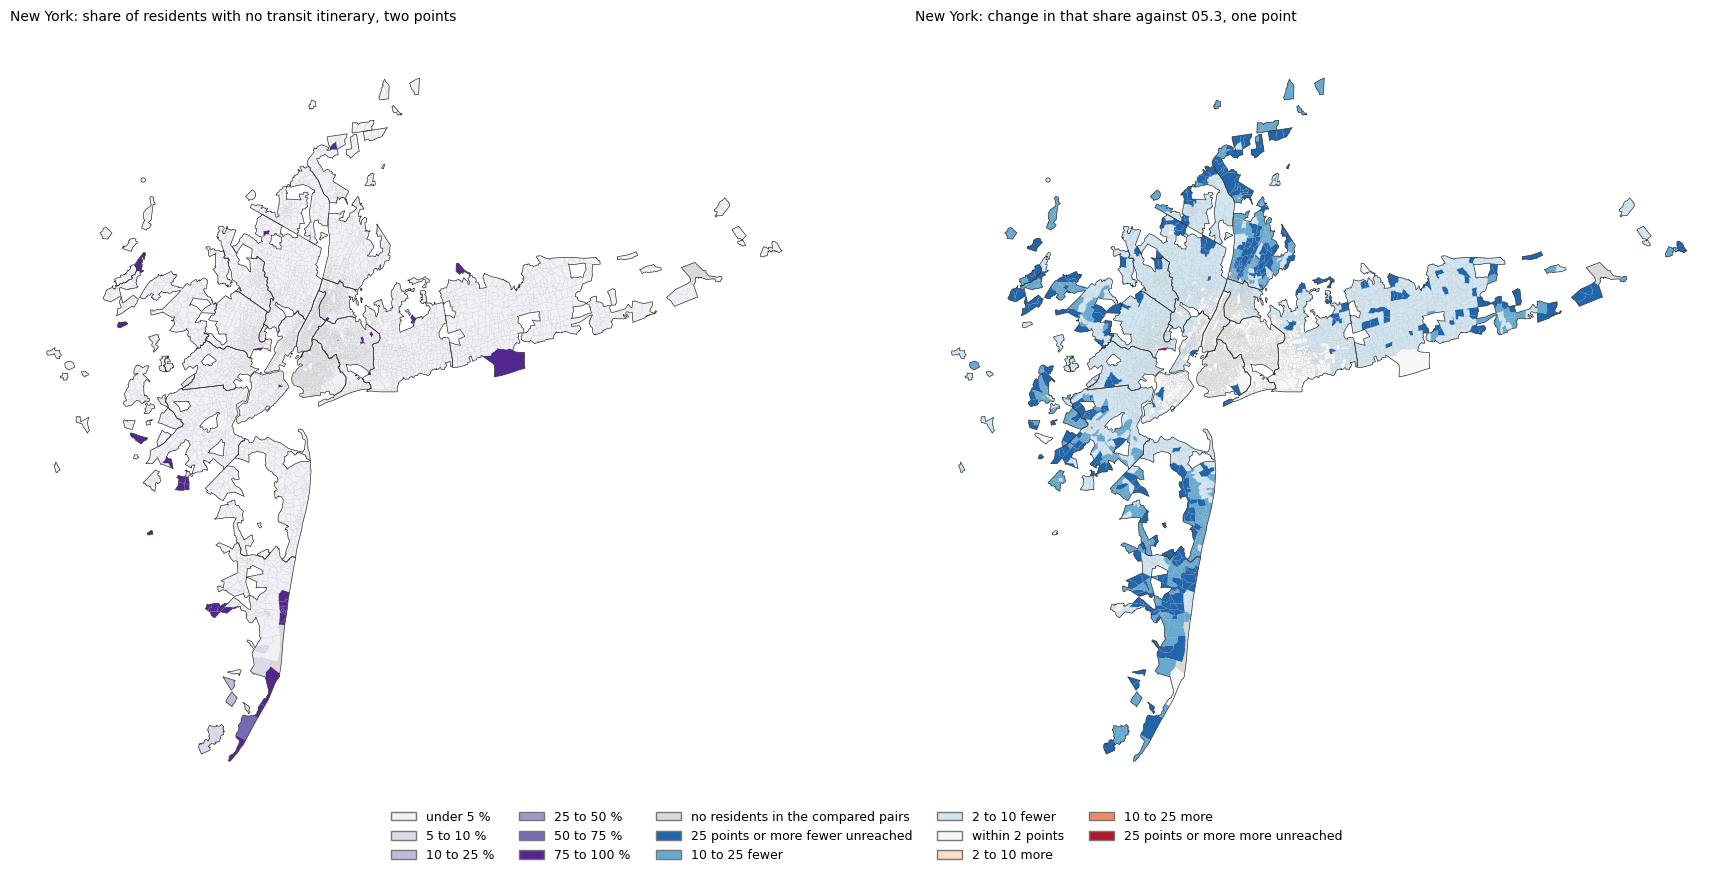

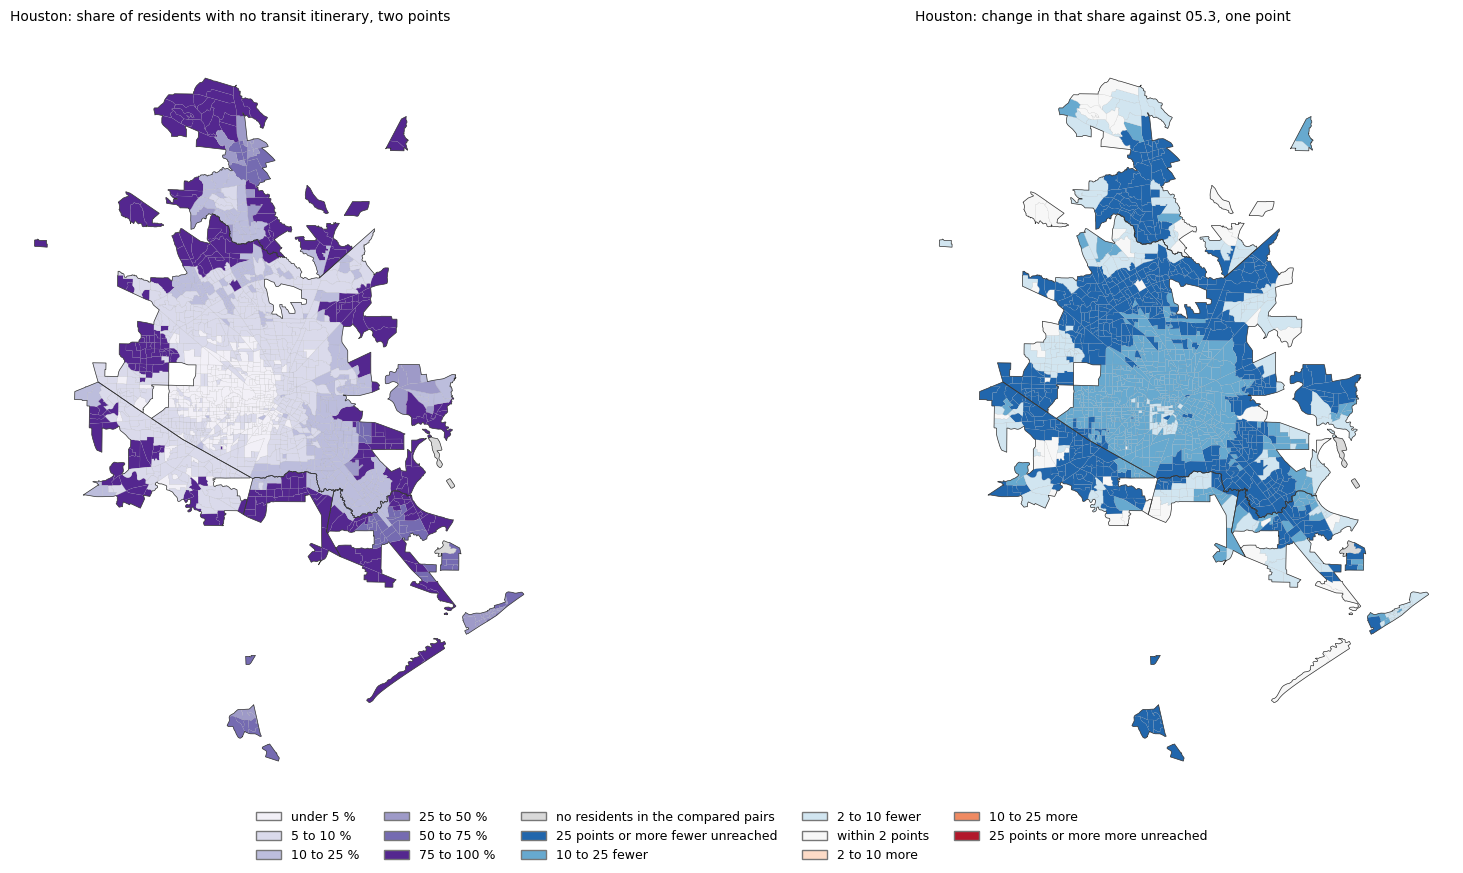

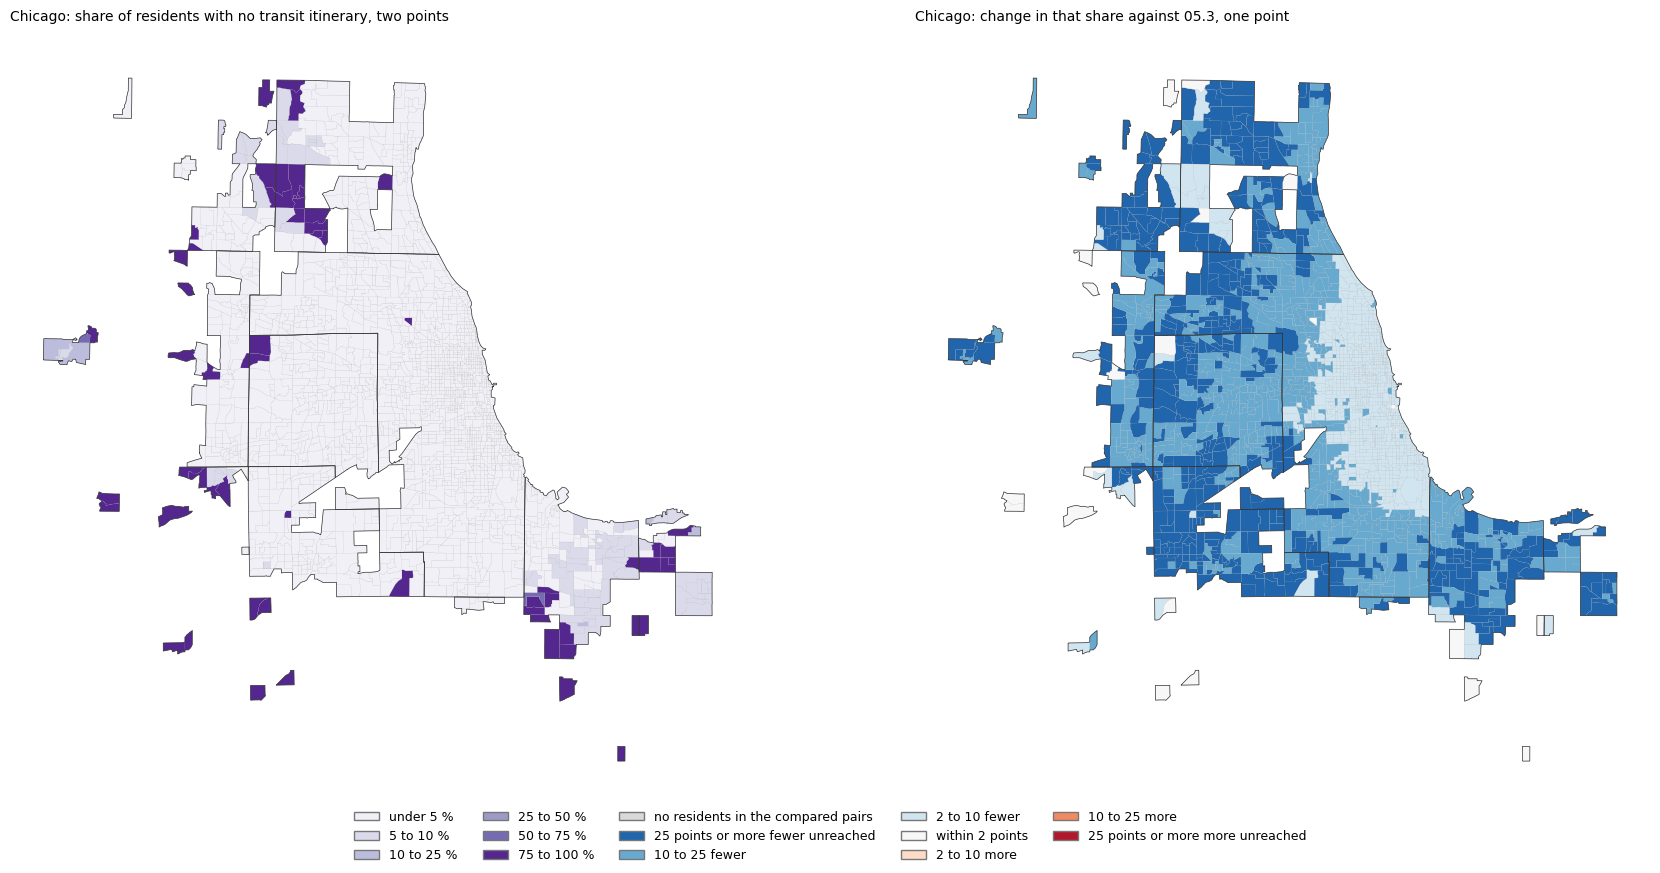

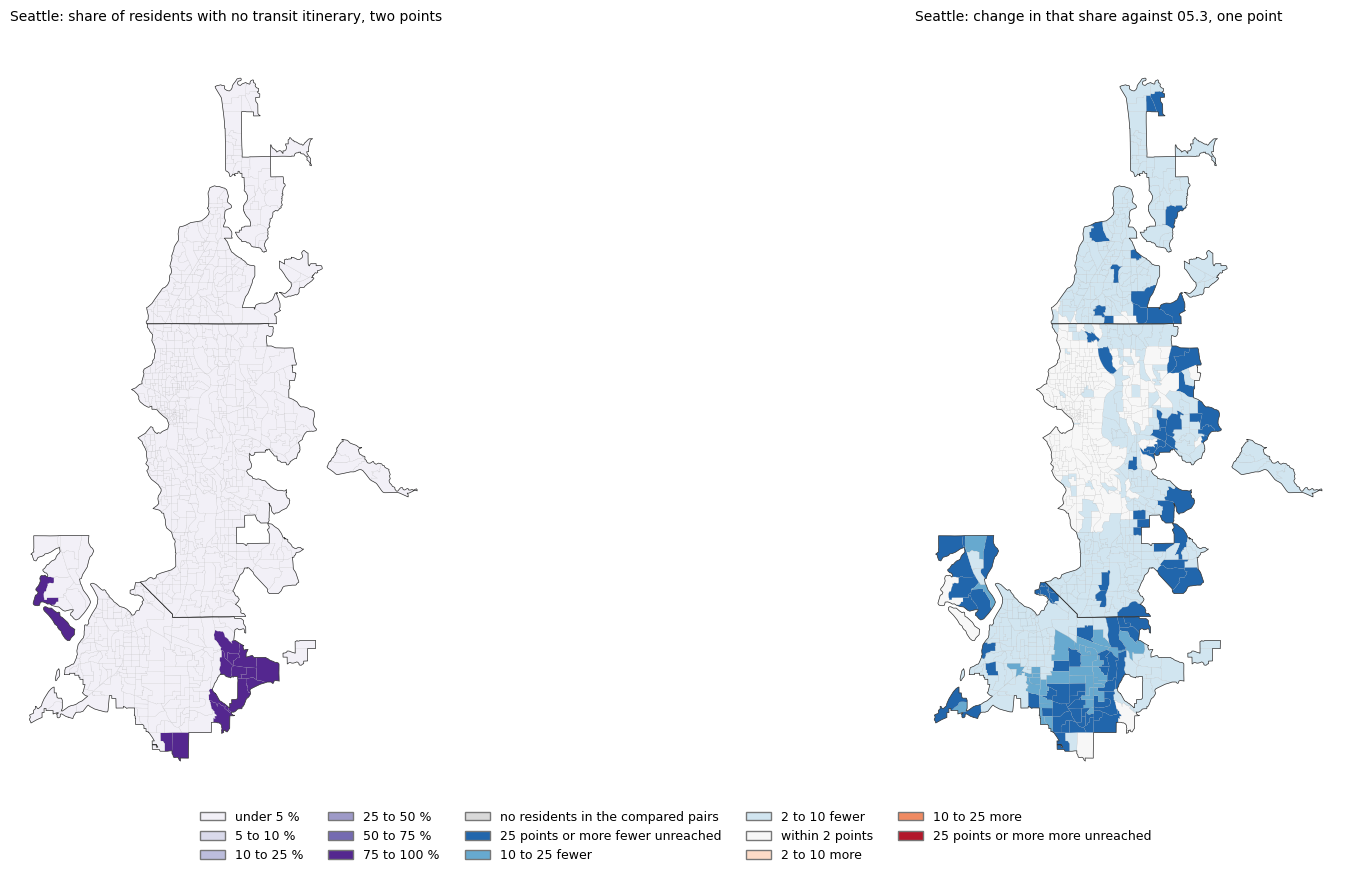

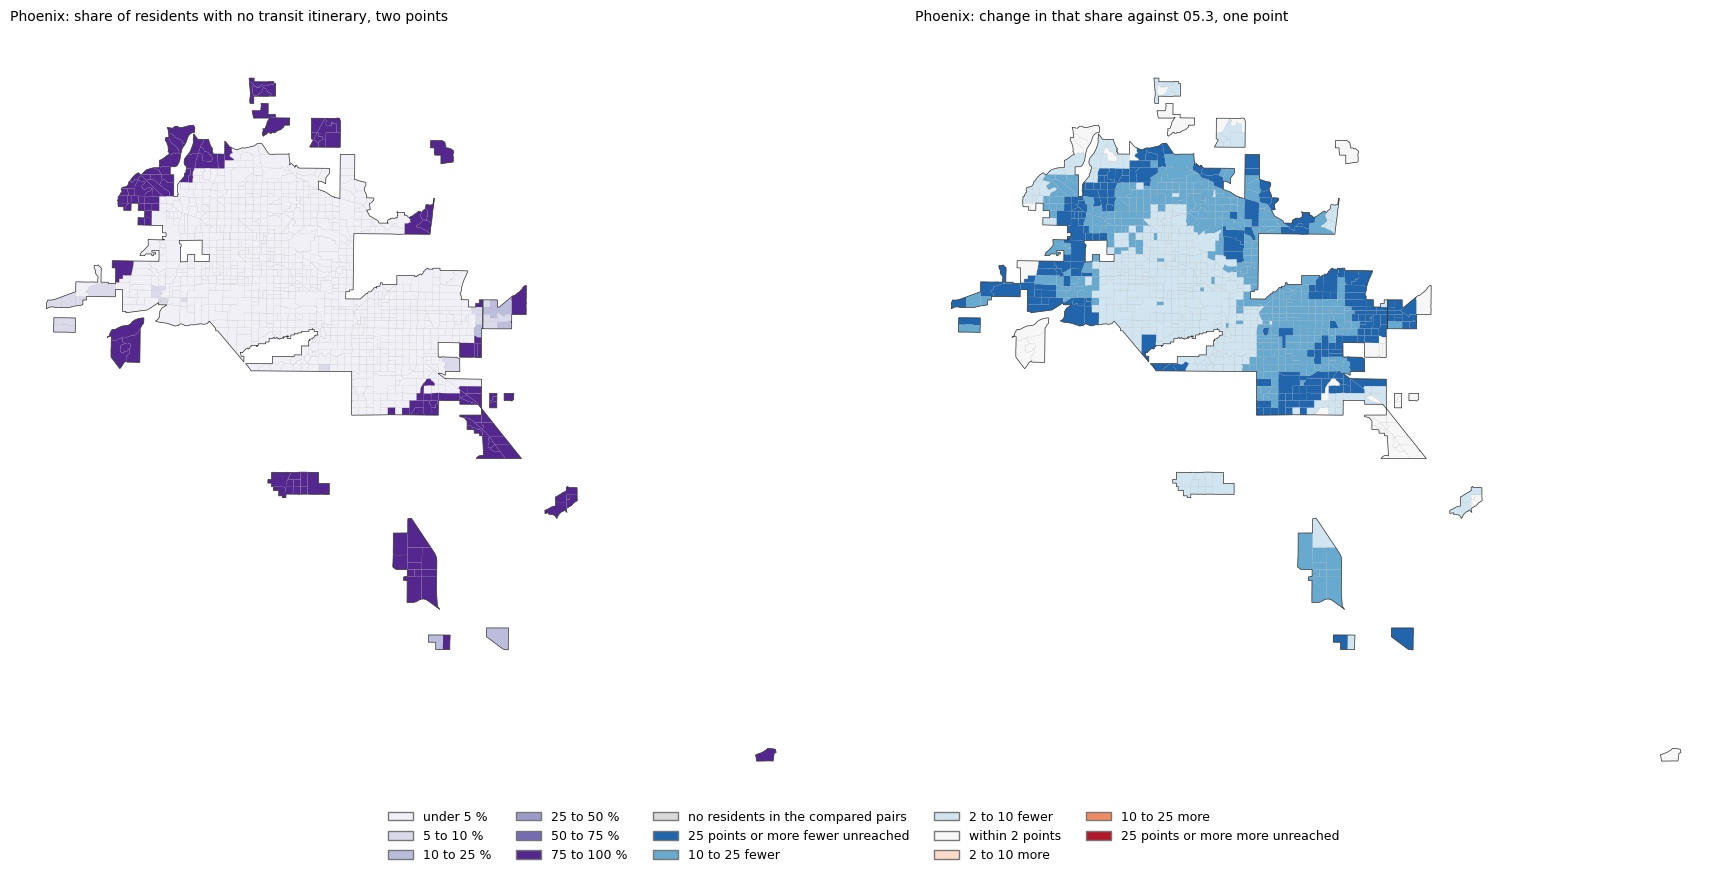

In [12]:
# By home county, and per home tract: the share of residents with no itinerary under each routing, over the between-tract pairs in both.
CHANGE_BINS = [-1.0000001, -0.25, -0.10, -0.02, 0.02, 0.10, 0.25, 1.0000001]
CHANGE_COLOURS = ["#2166ac", "#67a9cf", "#d1e5f0", "#f7f7f7", "#fddbc7", "#ef8a62", "#b2182b"]
CHANGE_LABELS = ["25 points or more fewer unreached", "10 to 25 fewer", "2 to 10 fewer", "within 2 points", "2 to 10 more", "10 to 25 more", "25 points or more more unreached"]
SHARE_BINS = [0, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0000001]
SHARE_COLOURS = ["#f2f0f7", "#dadaeb", "#bcbddc", "#9e9ac8", "#756bb1", "#54278f"]
SHARE_LABELS = ["under 5 %", "5 to 10 %", "10 to 25 %", "25 to 50 %", "50 to 75 %", "75 to 100 %"]

per_tract = {}
for area in AREAS:
    common = two_points[area].loc[two_points[area]["in_05_3"] & ~two_points[area]["within_tract"]]
    county = tracts[area].set_index("tract")["NAMELSADCO"]
    by_county = common.assign(county=common["from_id"].map(county)).groupby("county").apply(
        lambda rows: pd.Series({"commuters": rows["workers"].sum(),
                                "unreached, one point": rows.loc[rows["transit_one_point_min"].isna(), "workers"].sum() / rows["workers"].sum(),
                                "unreached, two points": rows.loc[rows["transit_two_points_min"].isna(), "workers"].sum() / rows["workers"].sum()}), include_groups=False)
    by_county["change, points"] = 100 * (by_county["unreached, two points"] - by_county["unreached, one point"])
    print(f"{area}: share of commuters with no transit itinerary by home county, between-tract pairs in both routings")
    display(by_county.sort_values("commuters", ascending=False).round(3))
    residents = common.groupby("from_id")["workers"].sum()
    table = pd.DataFrame({
        "residents": residents,
        "unreached_one": common.loc[common["transit_one_point_min"].isna()].groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents,
        "unreached_two": common.loc[common["transit_two_points_min"].isna()].groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents,
    }).rename_axis("tract").reset_index()
    table["change"] = table["unreached_two"] - table["unreached_one"]
    per_tract[area] = table
    print(f"{area}: home tracts whose unreached share moved by more than 10 points: {(table['change'] > 0.1).sum()} up, {(table['change'] < -0.1).sum()} down, of {len(table)}")


def reach_change_map(area):
    spec = AREAS[area]
    shown = tracts[area][["tract", "NAMELSADCO", "geometry"]].to_crs(spec["metric_crs"]).merge(per_tract[area], on="tract", how="left")
    counties = shown.dissolve("NAMELSADCO").boundary
    figure, axes = plt.subplots(ncols=2, figsize=(18, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    for axis, column, bins, colours, title in zip(axes, ["unreached_two", "change"], [SHARE_BINS, CHANGE_BINS], [SHARE_COLOURS, CHANGE_COLOURS],
                                                  ["share of residents with no transit itinerary, two points", "change in that share against 05.3, one point"]):
        shown.plot(ax=axis, color=class_colours(shown[column], bins, colours), edgecolor="#9a9a9a", linewidth=0.08)
        counties.plot(ax=axis, color="#333333", linewidth=0.5)
        axis.set_title(f"{area}: {title}", loc="left", fontsize=10)
        axis.set_aspect("equal")
        axis.set_axis_off()
    handles = [Patch(facecolor=c, edgecolor="#777777", label=l) for c, l in zip(SHARE_COLOURS, SHARE_LABELS)] + [Patch(facecolor=MISSING_COLOUR, edgecolor="#777777", label="no residents in the compared pairs")]
    handles += [Patch(facecolor=c, edgecolor="#777777", label=l) for c, l in zip(CHANGE_COLOURS, CHANGE_LABELS)]
    figure.legend(handles=handles, loc="outside lower center", ncol=5, frameon=False, fontsize=9)
    return figure


reach_change_map("New York");
reach_change_map("Houston");
reach_change_map("Chicago");
reach_change_map("Seattle");
reach_change_map("Phoenix");
